# Задание 3. Свои оптимизаторы

Основной оптимизатор, который я сдаю - AdamW (6 баллов). Дополнительно реализованы Momentum, RMSProp и Adam - по сути это "составные части" AdamW, и с ними удобно сравнивать. Идея описана для всех алгоритмов из списка в задании. Все написаны как наследники `torch.optim.Optimizer` с тем же API и теми же гиперпараметрами, что в `torch.optim`, поэтому их можно подставлять вместо стандартных (MyAdamW используется в задании 4).

План:
1. идея алгоритмов (подробнее всего - AdamW);
2. реализация;
3. тесты на `unittest`;
4. проверка на двумерной функции Розенброка;
5. сходимость на FashionMNIST: лосс, нормы градиентов, распределения весов.

## Идея алгоритмов

Обозначения: $\theta_t$ - параметры после $t$ шагов, $g_t = \nabla_\theta L(\theta_{t-1})$ - стохастический градиент на батче, $\eta$ - learning rate, все операции с векторами (квадрат, корень, деление) поэлементные. Обычный SGD делает $\theta_t = \theta_{t-1} - \eta g_t$, и у него две главные проблемы:
- в "оврагах" (линии уровня сильно вытянуты, гессиан плохо обусловлен) он скачет поперек оврага и медленно ползет вдоль него: lr ограничен самой крутой кривизной;
- один lr на все параметры, хотя масштабы градиентов у разных весов (и слоев) отличаются на порядки.

Первую проблему решают методы с моментом, вторую - адаптивные методы, Adam и его родственники пытаются решить обе.

### Momentum (heavy ball, Поляк 1964)

Копим "скорость" - экспоненциально затухающую сумму прошлых градиентов:
$$b_t = \mu b_{t-1} + g_t, \qquad \theta_t = \theta_{t-1} - \eta b_t .$$
Это шарик с инерцией, который катится по поверхности лосса. Вдоль оврага градиенты сонаправлены и складываются - эффективный шаг растет до $\eta/(1-\mu)$, т.е. при $\mu = 0.9$ в 10 раз. Поперек оврага знак градиента все время меняется, и эти компоненты взаимно гасятся. В torch на первом шаге $b_1 = g_1$, а weight decay добавляется к градиенту: $g_t \leftarrow g_t + \lambda\theta_{t-1}$.

### Nesterov (SGD с моментом Нестерова; Нестеров 1983, в виде для нейросетей - Sutskever et al. 2013)

Идея - считать градиент не в текущей точке, а там, куда нас и так унесет момент ("заглянуть вперед"):
$$b_t = \mu b_{t-1} + \nabla L(\theta_{t-1} - \eta\mu b_{t-1}), \qquad \theta_t = \theta_{t-1} - \eta b_t .$$
Если градиент в точке, куда мы летим, уже смотрит в другую сторону, метод раньше тормозит и меньше осциллирует. Считать градиент в другой точке неудобно, поэтому делают замену переменных $\tilde\theta = \theta - \eta\mu b$, и получается вариант из torch (`SGD(nesterov=True)`):
$$b_t = \mu b_{t-1} + g_t, \qquad \theta_t = \theta_{t-1} - \eta\,(g_t + \mu b_t).$$

### Adagrad (Duchi et al., 2011)

Свой lr для каждой координаты: делим на корень из суммы квадратов всех прошлых градиентов
$$G_t = G_{t-1} + g_t^2, \qquad \theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{G_t} + \varepsilon}\, g_t .$$
Координаты, по которым градиенты маленькие или редкие (редкие признаки, редкие слова в NLP), получают большой шаг, а "частые" - маленький, поэтому Adagrad хорошо работает на разреженных данных. Минус: $G_t$ только растет, эффективный lr $\eta/\sqrt{G_t}$ монотонно падает примерно как $1/\sqrt t$, и в глубоких сетях обучение "засыпает" раньше, чем сойдется.

### RMSProp (Hinton, Coursera, лекция 6e)

Чинит затухание Adagrad: вместо суммы берем экспоненциальное скользящее среднее, т.е. помним примерно $1/(1-\alpha)$ последних шагов:
$$v_t = \alpha v_{t-1} + (1-\alpha)\, g_t^2, \qquad \theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{v_t} + \varepsilon}\, g_t .$$
Поправки на смещение здесь нет, поэтому на первом шаге $v_1 = (1-\alpha) g_1^2$ и шаг равен $\eta/\sqrt{1-\alpha} = 10\eta$ (при $\alpha = 0.99$). В torch есть еще `momentum` (момент поверх нормированного градиента) и `centered` (делим на $\sqrt{v_t - \bar g_t^2}$, т.е. на оценку стандартного отклонения градиента, вместо $\sqrt{v_t}$) - их я тоже реализовал.

### Adadelta (Zeiler, 2012)

Тоже Adagrad с EMA, но Зейлер заметил, что в $\Delta\theta = -\eta g / \sqrt{v}$ "не сходятся единицы": шаг получается безразмерным, а должен иметь размерность $\theta$ (как у метода Ньютона $\Delta\theta = -H^{-1} g$). Поэтому глобальный lr заменяется на RMS прошлых шагов:
$$E[g^2]_t = \rho E[g^2]_{t-1} + (1-\rho) g_t^2, \qquad \Delta_t = \frac{\sqrt{E[\Delta^2]_{t-1} + \varepsilon}}{\sqrt{E[g^2]_t + \varepsilon}}\, g_t,$$
$$E[\Delta^2]_t = \rho E[\Delta^2]_{t-1} + (1-\rho) \Delta_t^2, \qquad \theta_t = \theta_{t-1} - \eta \Delta_t ,$$
где $\eta = 1$ по умолчанию (в torch оставлен как множитель). Отношение $\mathrm{RMS}[\Delta]/\mathrm{RMS}[g]$ - грубая оценка обратной кривизны. На практике старт очень медленный: первый шаг примерно $\sqrt{\varepsilon/(1-\rho)} \approx 3\cdot 10^{-3}$, и все сильно зависит от $\varepsilon$.

### Adam (Kingma & Ba, 2014)

Momentum + RMSProp: скользящие средние градиента (первый момент) и его квадрата (второй момент)
$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2 .$$
Так как $m_0 = v_0 = 0$, в начале оценки занижены: $\mathbb E[m_t] \approx (1-\beta_1^t)\,\mathbb E[g]$. Отсюда поправка на смещение (bias correction):
$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^t}, \qquad \theta_t = \theta_{t-1} - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \varepsilon}.$$
Шаг по каждой координате порядка $\eta$ и почти не зависит от масштаба градиента: на первом шаге он равен $\eta\, g_1/(|g_1| + \varepsilon) \approx \eta\,\mathrm{sign}(g_1)$, а умножение лосса на константу почти ничего не меняет, пока $|g| \gg \varepsilon$. То есть $\eta$ - это "размер шага в пространстве параметров". `weight_decay` в `torch.optim.Adam` - это L2-регуляризация: к градиенту добавляется $\lambda\theta_{t-1}$, и он дальше идет в $m_t$ и $v_t$.

### AdamW (Loshchilov & Hutter, 2017) - основной оптимизатор

Для обычного SGD L2-регуляризация и weight decay - одно и то же:
$$\theta_t = \theta_{t-1} - \eta\,(g_t + \lambda\theta_{t-1}) = (1 - \eta\lambda)\,\theta_{t-1} - \eta g_t ,$$
т.е. добавить $\frac{\lambda}{2}\|\theta\|^2$ к лоссу - то же самое, что на каждом шаге домножать веса на $(1-\eta\lambda)$. Для адаптивных методов это уже не так. В Adam с L2 слагаемое $\lambda\theta$ попадает в $m_t$ и $v_t$ и потом делится на $\sqrt{\hat v_t}$:
- у весов с большими градиентами (большое $v$) регуляризация почти исчезает, а у весов с маленькими градиентами она, наоборот, сильная - т.е. сила регуляризации зависит от истории градиентов, а не от $\lambda$;
- крайний случай: если градиент лосса нулевой, то $g = \lambda\theta$, после нормировки шаг $\approx \eta\,\mathrm{sign}(\theta)$ - каждый вес сдвигается на $\eta$ вне зависимости от его величины, а не уменьшается пропорционально (это проверяется в тестах).

Лощилов и Хуттер предложили "развязать" (decouple) weight decay и адаптивный шаг: нормировка применяется только к градиенту лосса, а веса отдельно уменьшаются с одной и той же для всех скоростью:
$$\theta_{t-1} \leftarrow (1 - \eta\lambda)\,\theta_{t-1},$$
$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2,$$
$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^t}, \qquad \theta_t = \theta_{t-1} - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t} + \varepsilon}.$$
Здесь $g_t$ - чистый градиент лосса, без $\lambda\theta$. В статье decay записан как $\eta_t\lambda\theta$ с множителем расписания $\eta_t$, в torch он умножается на текущий lr - так и сделано (тогда при изменении lr шедулером decay меняется вместе с ним).

Что это дает:
- все веса затухают с одной и той же относительной скоростью $\eta\lambda$ за шаг, как и задумано у weight decay; при нулевом градиенте $\theta_k = (1-\eta\lambda)^k \theta_0$;
- в статье показано, что у AdamW оптимальные $\eta$ и $\lambda$ почти независимы (у Adam с L2 они сильно связаны), и обобщающая способность лучше, чем у Adam с L2, - на уровне SGD с моментом. Поэтому сейчас AdamW - стандарт, например, для трансформеров.

По умолчанию в torch $\eta = 10^{-3}$, $\beta = (0.9, 0.999)$, $\varepsilon = 10^{-8}$, $\lambda = 10^{-2}$. Еще поддержан флаг `amsgrad` (Reddi et al., 2018): в знаменателе вместо $v_t$ берется $\max(v_1, \dots, v_t)$, чтобы эффективный lr не рос.

### Nadam (Dozat, 2016)

Adam + момент Нестерова: в числителе вместо $\hat m_t$ берется "заглядывающая вперед" комбинация текущего градиента и момента. В torch еще используется расписание момента $\mu_t = \beta_1\,(1 - 0.5\cdot 0.96^{t\psi})$, $\psi$ = `momentum_decay` $= 0.004$ (момент растет от $\approx 0.45$ до $\beta_1$ очень медленно: к 4000-му шагу это только $\approx 0.66$, а близко к $0.9$ он становится через $\sim 30$ тыс. шагов):
$$\theta_t = \theta_{t-1} - \eta\left[\frac{1-\mu_t}{1-\prod_{i\le t}\mu_i}\, g_t + \frac{\mu_{t+1}}{1-\prod_{i\le t+1}\mu_i}\, m_t\right] \Big/ \left(\sqrt{\hat v_t} + \varepsilon\right).$$

In [1]:
import contextlib
import copy
import inspect
import io
import math
import time
import unittest

import matplotlib.pyplot as plt
from matplotlib import ticker
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn

from utils import BaseNetwork, set_seed, load_fashion_mnist, iterate_batches, grad_norm, evaluate

## Реализация

Все оптимизаторы - наследники `torch.optim.Optimizer`, но от него берется только хранение групп параметров и состояния, `zero_grad` и `state_dict` / `load_state_dict`. Сам шаг написан руками через in-place операции над тензорами под `torch.no_grad()`. Общий цикл по параметрам (пропуск `grad is None`, ленивое создание состояния, `closure`) вынесен в базовый класс `MyOptimizerBase`, наследники описывают только начальное состояние и формулу обновления.

Имена гиперпараметров и их значения по умолчанию такие же, как в `torch.optim` (кроме `momentum=0.9` у `MyMomentum`: у `SGD` в torch по умолчанию 0, но с нулевым моментом это был бы просто SGD; варианта Нестерова (`nesterov=True`) у меня нет). Служебные флаги torch (`maximize`, `foreach`, `fused`, `capturable`, `differentiable`) я не делал. Порядок операций (куда добавляется $\varepsilon$, как считаются поправки на смещение, что происходит на первом шаге) я сверял с исходниками `torch/optim/*.py`, чтобы траектории совпадали с torch и это можно было проверить тестами. Некорректные гиперпараметры дают `ValueError`, как в torch.

In [2]:
def _check_hparam(ok, name, value):
    if not ok:
        raise ValueError(f"Invalid {name} value: {value}")


class MyOptimizerBase(torch.optim.Optimizer):
    """Общий каркас для моих оптимизаторов.

    От torch.optim.Optimizer берется только хранение param_groups / state,
    zero_grad и state_dict / load_state_dict. Сам шаг считается в наследниках:
    _init_state(p, group) - начальное состояние параметра (создается лениво,
    при первом шаге, когда у параметра появился градиент),
    _update(p, grad, state, group) - in-place обновление параметра.
    """

    def _init_state(self, p, group):
        return {}

    def _update(self, p, grad, state, group):
        raise NotImplementedError

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                if p.grad.is_sparse:
                    raise RuntimeError(f"{type(self).__name__} не поддерживает разреженные градиенты")
                state = self.state[p]
                if len(state) == 0:
                    state.update(self._init_state(p, group))
                self._update(p, p.grad, state, group)
        return loss

In [3]:
class MyMomentum(MyOptimizerBase):
    r"""SGD с моментом (heavy ball, Поляк 1964). Аналог torch.optim.SGD(momentum=mu, nesterov=False).

    g_t = grad + wd * p
    b_1 = g_1,  b_t = mu * b_{t-1} + (1 - dampening) * g_t
    p_t = p_{t-1} - lr * b_t
    """

    def __init__(self, params, lr=1e-3, momentum=0.9, dampening=0, weight_decay=0):
        _check_hparam(lr >= 0.0, "learning rate", lr)
        _check_hparam(momentum >= 0.0, "momentum", momentum)
        _check_hparam(0.0 <= dampening <= 1.0, "dampening", dampening)
        _check_hparam(weight_decay >= 0.0, "weight_decay", weight_decay)
        defaults = dict(lr=lr, momentum=momentum, dampening=dampening, weight_decay=weight_decay)
        super().__init__(params, defaults)

    def _init_state(self, p, group):
        return {"momentum_buffer": None}

    def _update(self, p, grad, state, group):
        lr, mu, wd = group["lr"], group["momentum"], group["weight_decay"]
        if wd != 0:
            grad = grad.add(p, alpha=wd)
        if mu != 0:
            buf = state["momentum_buffer"]
            if buf is None:
                # на первом шаге буфер просто равен градиенту (как в torch)
                buf = state["momentum_buffer"] = grad.clone()
            else:
                buf.mul_(mu).add_(grad, alpha=1 - group["dampening"])
            grad = buf
        p.add_(grad, alpha=-lr)

In [4]:
class MyRMSProp(MyOptimizerBase):
    r"""RMSProp (Hinton, лекция 6e). Аналог torch.optim.RMSprop.

    g_t = grad + wd * p
    v_t = alpha * v_{t-1} + (1 - alpha) * g_t^2
    centered: m_t = alpha * m_{t-1} + (1 - alpha) * g_t,  d_t = sqrt(v_t - m_t^2) + eps
    иначе:    d_t = sqrt(v_t) + eps
    momentum > 0: b_t = momentum * b_{t-1} + g_t / d_t,  p_t = p_{t-1} - lr * b_t
    иначе:        p_t = p_{t-1} - lr * g_t / d_t
    """

    def __init__(self, params, lr=1e-2, alpha=0.99, eps=1e-8, weight_decay=0, momentum=0, centered=False):
        _check_hparam(lr >= 0.0, "learning rate", lr)
        _check_hparam(0.0 <= alpha <= 1.0, "alpha", alpha)
        _check_hparam(eps >= 0.0, "epsilon", eps)
        _check_hparam(weight_decay >= 0.0, "weight_decay", weight_decay)
        _check_hparam(momentum >= 0.0, "momentum", momentum)
        defaults = dict(lr=lr, alpha=alpha, eps=eps, weight_decay=weight_decay,
                        momentum=momentum, centered=centered)
        super().__init__(params, defaults)

    def _init_state(self, p, group):
        state = {"step": 0, "square_avg": torch.zeros_like(p)}
        if group["momentum"] > 0:
            state["momentum_buffer"] = torch.zeros_like(p)
        if group["centered"]:
            state["grad_avg"] = torch.zeros_like(p)
        return state

    def _update(self, p, grad, state, group):
        alpha = group["alpha"]
        state["step"] += 1
        if group["weight_decay"] != 0:
            grad = grad.add(p, alpha=group["weight_decay"])
        square_avg = state["square_avg"]
        square_avg.mul_(alpha).addcmul_(grad, grad, value=1 - alpha)
        if group["centered"]:
            grad_avg = state["grad_avg"]
            grad_avg.lerp_(grad, 1 - alpha)  # = alpha * m + (1 - alpha) * g
            avg = square_avg.addcmul(grad_avg, grad_avg, value=-1).sqrt_()
        else:
            avg = square_avg.sqrt()
        avg.add_(group["eps"])
        if group["momentum"] > 0:
            buf = state["momentum_buffer"]
            buf.mul_(group["momentum"]).addcdiv_(grad, avg)
            p.add_(buf, alpha=-group["lr"])
        else:
            p.addcdiv_(grad, avg, value=-group["lr"])

In [5]:
class MyAdam(MyOptimizerBase):
    r"""Adam (Kingma & Ba, 2014). Аналог torch.optim.Adam, weight_decay - это L2 в градиенте.

    g_t = grad + wd * p
    m_t = beta1 * m_{t-1} + (1 - beta1) * g_t
    v_t = beta2 * v_{t-1} + (1 - beta2) * g_t^2      (amsgrad: v_max = max(v_max, v_t))
    p_t = p_{t-1} - lr / (1 - beta1^t) * m_t / (sqrt(v_t / (1 - beta2^t)) + eps)
    """

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0, amsgrad=False):
        _check_hparam(lr >= 0.0, "learning rate", lr)
        _check_hparam(eps >= 0.0, "epsilon", eps)
        _check_hparam(0.0 <= betas[0] < 1.0, "beta1", betas[0])
        _check_hparam(0.0 <= betas[1] < 1.0, "beta2", betas[1])
        _check_hparam(weight_decay >= 0.0, "weight_decay", weight_decay)
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, amsgrad=amsgrad)
        super().__init__(params, defaults)

    def _init_state(self, p, group):
        state = {"step": 0, "exp_avg": torch.zeros_like(p), "exp_avg_sq": torch.zeros_like(p)}
        if group["amsgrad"]:
            state["max_exp_avg_sq"] = torch.zeros_like(p)
        return state

    def _update(self, p, grad, state, group):
        beta1, beta2 = group["betas"]
        state["step"] += 1
        t = state["step"]
        if group["weight_decay"] != 0:
            grad = grad.add(p, alpha=group["weight_decay"])
        exp_avg, exp_avg_sq = state["exp_avg"], state["exp_avg_sq"]
        exp_avg.lerp_(grad, 1 - beta1)  # = beta1 * m + (1 - beta1) * g
        exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
        if group["amsgrad"]:
            torch.maximum(state["max_exp_avg_sq"], exp_avg_sq, out=state["max_exp_avg_sq"])
            exp_avg_sq = state["max_exp_avg_sq"]
        bias_correction1 = 1 - beta1 ** t
        bias_correction2 = 1 - beta2 ** t
        denom = (exp_avg_sq.sqrt() / bias_correction2 ** 0.5).add_(group["eps"])
        p.addcdiv_(exp_avg, denom, value=-group["lr"] / bias_correction1)

Основной оптимизатор - AdamW. Он самодостаточный (зависит только от `MyOptimizerBase` и `_check_hparam`), чтобы его было удобно использовать в задании 4.

In [6]:
class MyAdamW(MyOptimizerBase):
    r"""AdamW (Loshchilov & Hutter, 2017): Adam с отделенным (decoupled) weight decay.
    Аналог torch.optim.AdamW, можно подставлять вместо него.

    p <- p * (1 - lr * wd)                              # weight decay мимо адаптивной нормировки
    m_t = beta1 * m_{t-1} + (1 - beta1) * g_t
    v_t = beta2 * v_{t-1} + (1 - beta2) * g_t^2         (amsgrad: v_max = max(v_max, v_t))
    m_hat = m_t / (1 - beta1^t),  v_hat = v_t / (1 - beta2^t)
    p <- p - lr * m_hat / (sqrt(v_hat) + eps)
    """

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, amsgrad=False):
        _check_hparam(lr >= 0.0, "learning rate", lr)
        _check_hparam(eps >= 0.0, "epsilon", eps)
        _check_hparam(0.0 <= betas[0] < 1.0, "beta1", betas[0])
        _check_hparam(0.0 <= betas[1] < 1.0, "beta2", betas[1])
        _check_hparam(weight_decay >= 0.0, "weight_decay", weight_decay)
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, amsgrad=amsgrad)
        super().__init__(params, defaults)

    def _init_state(self, p, group):
        state = {"step": 0, "exp_avg": torch.zeros_like(p), "exp_avg_sq": torch.zeros_like(p)}
        if group["amsgrad"]:
            state["max_exp_avg_sq"] = torch.zeros_like(p)
        return state

    def _update(self, p, grad, state, group):
        lr, (beta1, beta2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
        state["step"] += 1
        t = state["step"]

        # 1) decoupled weight decay: уменьшаем сами веса, градиент не трогаем
        if wd != 0:
            p.mul_(1 - lr * wd)

        # 2) скользящие средние градиента и его квадрата
        exp_avg, exp_avg_sq = state["exp_avg"], state["exp_avg_sq"]
        exp_avg.lerp_(grad, 1 - beta1)  # = beta1 * m + (1 - beta1) * g
        exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
        if group["amsgrad"]:
            torch.maximum(state["max_exp_avg_sq"], exp_avg_sq, out=state["max_exp_avg_sq"])
            exp_avg_sq = state["max_exp_avg_sq"]

        # 3) поправки на смещение (m_0 = v_0 = 0) и сам шаг
        bias_correction1 = 1 - beta1 ** t
        bias_correction2 = 1 - beta2 ** t
        denom = (exp_avg_sq.sqrt() / bias_correction2 ** 0.5).add_(eps)
        p.addcdiv_(exp_avg, denom, value=-lr / bias_correction1)

In [7]:
MY_OPTIMIZERS = {"Momentum": MyMomentum, "RMSProp": MyRMSProp, "Adam": MyAdam, "AdamW": MyAdamW}

## Тесты

Тесты на `unittest`, разбиты на группы:
1. `TestTorchEquivalence` - главное: на маленькой сети и случайных данных делаем 40 шагов моим оптимизатором и его аналогом из `torch.optim` из одной и той же начальной точки и сравниваем параметры (`assert_close`, rtol=1e-6). Для каждого оптимизатора несколько наборов гиперпараметров (weight decay, другие betas / momentum, centered, amsgrad, ...), отдельно две группы параметров с разными lr и параметры в float64.
2. `TestHandComputedSteps` - первые шаги, посчитанные руками, и свойства алгоритмов: два шага AdamW с weight decay целиком руками (без сравнения с torch); первый шаг Momentum - обычный SGD; первый шаг Adam / AdamW равен $\eta\,\mathrm{sign}(g)$ (с точностью до $\varepsilon$) при любом масштабе градиента, у RMSProp он в $1/\sqrt{1-\alpha} = 10$ раз больше; AdamW при нулевом градиенте просто умножает веса на $(1-\eta\lambda)$, а Adam с L2 сдвигает все веса на $\eta$; адаптивные методы почти не замечают умножения лосса на константу (при маленьком $\varepsilon$).
3. `TestConvergence` - сходимость на плохо обусловленной квадратичной функции (оси повернуты, число обусловленности 100) и на функции Розенброка. На Розенброке порог свой для каждого метода: от Momentum, Adam и AdamW требую почти точной сходимости ($f < 10^{-6}$), от RMSProp - хотя бы дойти до дна оврага.
4. `TestOptimizerApi` - параметры с `grad = None` пропускаются, состояние создается лениво, работают `closure`, `zero_grad` и `lr_scheduler`.
5. `TestStateDict` - сохранение и загрузка `state_dict` посередине обучения дают тот же результат, что и обучение без перерыва.
6. `TestInvalidHparams` - некорректные гиперпараметры дают `ValueError`.

Перебор оптимизаторов и конфигураций сделан через `subTest`. Тесты запускаю в один поток torch - на крошечных тензорах многопоточность только тормозит.

In [8]:
# torch-аналоги моих оптимизаторов (класс + параметры, которые фиксируют вариант алгоритма)
TORCH_TWINS = {
    "Momentum": (torch.optim.SGD, {"momentum": 0.9}),
    "RMSProp": (torch.optim.RMSprop, {}),
    "Adam": (torch.optim.Adam, {}),
    "AdamW": (torch.optim.AdamW, {}),
}


def make_torch_twin(name, params, **kwargs):
    cls, fixed = TORCH_TWINS[name]
    return cls(params, **{**fixed, **kwargs})


def default_lr(name):
    return inspect.signature(MY_OPTIMIZERS[name]).parameters["lr"].default


def make_toy_problem(seed=0, dtype=torch.float32):
    """Маленькая сеть и случайные данные для тестов (full batch, все детерминировано)."""
    gen = torch.Generator().manual_seed(seed)
    x = torch.randn(64, 10, generator=gen)
    y = torch.randint(0, 3, (64,), generator=gen)
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(10, 16), nn.Tanh(), nn.Linear(16, 3))
    return model.to(dtype), x.to(dtype), y


def train_toy(make_opt, steps=40, seed=0, groups=False, loss_scale=1.0, model=None, opt=None, dtype=torch.float32):
    """Обучает игрушечную модель steps шагов. make_opt(params) -> оптимизатор.
    groups=True - две группы параметров (второй слой с другим lr, см. make_opt)."""
    toy_model, x, y = make_toy_problem(seed, dtype)
    model = model if model is not None else toy_model
    if opt is None:
        params = [{"params": model[0].parameters()}, {"params": model[2].parameters()}] if groups else model.parameters()
        opt = make_opt(params)
    losses = []
    for _ in range(steps):
        loss = loss_scale * F.cross_entropy(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return model, opt, losses


@contextlib.contextmanager
def torch_threads(n):
    """Временно меняет число потоков torch (на крошечных тензорах потоки только мешают)."""
    old = torch.get_num_threads()
    torch.set_num_threads(n)
    try:
        yield
    finally:
        torch.set_num_threads(old)


def run_opt_tests(*cases):
    suite = unittest.TestSuite([unittest.defaultTestLoader.loadTestsFromTestCase(c) for c in cases])
    log = io.StringIO()
    with torch_threads(1):
        result = unittest.TextTestRunner(verbosity=2, stream=log).run(suite)
    print(log.getvalue())
    return result

In [9]:
EQUIV_CONFIGS = {
    "Momentum": [{"lr": 0.05}, {"lr": 0.02, "momentum": 0.5, "weight_decay": 1e-2}, {"lr": 0.05, "dampening": 0.3}],
    "RMSProp": [{}, {"lr": 1e-3, "alpha": 0.9, "momentum": 0.9}, {"centered": True, "weight_decay": 1e-2}],
    "Adam": [{}, {"lr": 1e-2, "betas": (0.8, 0.99), "weight_decay": 1e-2}, {"amsgrad": True}],
    "AdamW": [{}, {"lr": 1e-2, "betas": (0.8, 0.99), "weight_decay": 0.1}, {"amsgrad": True, "weight_decay": 0.05}],
}


class TestTorchEquivalence(unittest.TestCase):
    """Траектории моих оптимизаторов совпадают с torch.optim на одинаковой задаче."""

    steps = 40
    tol = dict(rtol=1e-6, atol=1e-7)

    def _compare(self, name, make_mine, make_ref, groups=False, dtype=torch.float32):
        mine, _, mine_losses = train_toy(make_mine, self.steps, groups=groups, dtype=dtype)
        ref, _, ref_losses = train_toy(make_ref, self.steps, groups=groups, dtype=dtype)
        for p_mine, p_ref in zip(mine.parameters(), ref.parameters()):
            torch.testing.assert_close(p_mine, p_ref, **self.tol)
        self.assertAlmostEqual(mine_losses[-1], ref_losses[-1], places=6)
        # и параметры действительно сдвинулись, т.е. сравнение не тривиальное
        start, _, _ = train_toy(make_mine, 0, groups=groups, dtype=dtype)
        moved = max((a - b).abs().max().item() for a, b in zip(mine.parameters(), start.parameters()))
        self.assertGreater(moved, 1e-3)

    def test_same_trajectory(self):
        """40 шагов совпадают с torch.optim для разных гиперпараметров."""
        for name, configs in EQUIV_CONFIGS.items():
            for cfg in configs:
                with self.subTest(optimizer=name, **cfg):
                    self._compare(name, lambda ps: MY_OPTIMIZERS[name](ps, **cfg),
                                  lambda ps: make_torch_twin(name, ps, **cfg))

    def test_two_param_groups(self):
        """Две группы параметров со своими lr и weight_decay."""
        # у второй группы свой lr (в 3 раза меньше) и weight decay
        for name in MY_OPTIMIZERS:
            with self.subTest(optimizer=name):
                lr = default_lr(name) if name != "Momentum" else 0.05

                def with_groups(factory, params):
                    first, second = params
                    second = {**second, "lr": lr / 3, "weight_decay": 1e-2}
                    return factory([first, second], lr=lr)

                self._compare(name, lambda ps: with_groups(MY_OPTIMIZERS[name], ps),
                              lambda ps: with_groups(lambda g, **kw: make_torch_twin(name, g, **kw), ps),
                              groups=True)

    def test_float64(self):
        """В float64 траектории тоже совпадают."""
        for name in MY_OPTIMIZERS:
            cfg = EQUIV_CONFIGS[name][-1]
            with self.subTest(optimizer=name, **cfg):
                self._compare(name, lambda ps: MY_OPTIMIZERS[name](ps, **cfg),
                              lambda ps: make_torch_twin(name, ps, **cfg), dtype=torch.float64)


run_opt_tests(TestTorchEquivalence);

test_float64 (__main__.TestTorchEquivalence.test_float64)
В float64 траектории тоже совпадают. ... ok
test_same_trajectory (__main__.TestTorchEquivalence.test_same_trajectory)
40 шагов совпадают с torch.optim для разных гиперпараметров. ... ok
test_two_param_groups (__main__.TestTorchEquivalence.test_two_param_groups)
Две группы параметров со своими lr и weight_decay. ... ok

----------------------------------------------------------------------
Ran 3 tests in 1.202s

OK



In [10]:
class TestHandComputedSteps(unittest.TestCase):
    """Первые шаги, посчитанные руками, и свойства алгоритмов."""

    def setUp(self):
        self.p0 = torch.tensor([1.0, -2.0, 3.0, -0.5])
        self.g1 = torch.tensor([0.5, -1.0, 2.0, 0.3])
        self.g2 = torch.tensor([-0.2, 0.4, 1.0, -0.6])

    def _steps(self, opt_cls, grads, dtype=torch.float32, **kwargs):
        """Делает шаги с заданными градиентами, возвращает параметр после каждого шага."""
        p = nn.Parameter(self.p0.clone().to(dtype))
        opt = opt_cls([p], **kwargs)
        history = []
        for g in grads:
            p.grad = g.clone().to(dtype)
            opt.step()
            history.append(p.detach().clone())
        return history

    def test_momentum_first_steps(self):
        """Momentum: первые два шага руками."""
        lr, mu = 0.1, 0.9
        p1, p2 = self._steps(MyMomentum, [self.g1, self.g2], lr=lr, momentum=mu)
        torch.testing.assert_close(p1, self.p0 - lr * self.g1)  # первый шаг - обычный SGD
        torch.testing.assert_close(p2, p1 - lr * (mu * self.g1 + self.g2))

    def test_sgd_step_scales_with_gradient(self):
        """Momentum: шаг пропорционален градиенту."""
        # у SGD шаг пропорционален градиенту - в отличие от адаптивных методов ниже
        (p_small,) = self._steps(MyMomentum, [self.g1], lr=0.1)
        (p_big,) = self._steps(MyMomentum, [100 * self.g1], lr=0.1)
        torch.testing.assert_close(self.p0 - p_big, 100 * (self.p0 - p_small))

    def test_adaptive_first_step_is_lr_sign(self):
        """Adam/AdamW: первый шаг ~ lr * sign(g) при любом масштабе g."""
        # точнее, lr * g / (|g| + eps), отличие от lr * sign(g) меньше допуска
        lr = 0.01
        for cls, kw in ((MyAdam, {}), (MyAdamW, {"weight_decay": 0})):
            for scale in (1e-3, 1.0, 1e3):
                with self.subTest(optimizer=cls.__name__, scale=scale):
                    (p1,) = self._steps(cls, [scale * self.g1], lr=lr, **kw)
                    torch.testing.assert_close(p1, self.p0 - lr * self.g1.sign(), rtol=1e-5, atol=1e-6)

    def test_rmsprop_first_step(self):
        """RMSProp: первый шаг = lr / sqrt(1 - alpha) * sign(g)."""
        # без поправки на смещение первый шаг в 1/sqrt(1 - alpha) = 10 раз больше lr
        lr, alpha = 0.01, 0.99
        (p1,) = self._steps(MyRMSProp, [self.g1], lr=lr, alpha=alpha)
        torch.testing.assert_close(p1, self.p0 - lr / math.sqrt(1 - alpha) * self.g1.sign(), rtol=1e-5, atol=1e-6)

    def test_adamw_two_steps_by_hand(self):
        """AdamW: два шага с weight decay, посчитанные руками (float64)."""
        lr, wd, (b1, b2), eps = 0.1, 0.1, (0.9, 0.999), 1e-8
        p0, g1, g2 = self.p0.double(), self.g1.double(), self.g2.double()
        p1, p2 = self._steps(MyAdamW, [g1, g2], lr=lr, weight_decay=wd, dtype=torch.float64)
        # шаг 1: m_hat = g1, v_hat = g1^2, decay применяется к p0
        m1, v1 = (1 - b1) * g1, (1 - b2) * g1 ** 2
        expected1 = p0 * (1 - lr * wd) - lr * (m1 / (1 - b1)) / ((v1 / (1 - b2)).sqrt() + eps)
        torch.testing.assert_close(p1, expected1, rtol=1e-12, atol=1e-12)
        # шаг 2: поправки на смещение 1 - b1^2 и 1 - b2^2, decay применяется к p1
        m2, v2 = b1 * m1 + (1 - b1) * g2, b2 * v1 + (1 - b2) * g2 ** 2
        expected2 = p1 * (1 - lr * wd) - lr * (m2 / (1 - b1 ** 2)) / ((v2 / (1 - b2 ** 2)).sqrt() + eps)
        torch.testing.assert_close(p2, expected2, rtol=1e-12, atol=1e-12)

    def test_adamw_zero_grad_only_decays(self):
        """AdamW при нулевом градиенте: p_k = (1 - lr*wd)^k * p_0."""
        # при нулевом градиенте AdamW просто умножает веса на (1 - lr * wd) на каждом шаге
        lr, wd, k = 0.1, 0.5, 5
        history = self._steps(MyAdamW, [torch.zeros(4)] * k, lr=lr, weight_decay=wd)
        for i, p in enumerate(history, start=1):
            torch.testing.assert_close(p, self.p0 * (1 - lr * wd) ** i)

    def test_adam_l2_is_not_weight_decay(self):
        """Adam с L2 при нулевом градиенте сдвигает все веса на lr, AdamW - пропорционально."""
        # у Adam с L2 штраф wd * p проходит через нормировку: все веса уменьшаются на ~lr,
        # независимо от их величины (большие веса почти не штрафуются относительно)
        lr, wd = 0.01, 0.5
        (p_adam,) = self._steps(MyAdam, [torch.zeros(4)], lr=lr, weight_decay=wd)
        torch.testing.assert_close(p_adam, self.p0 - lr * self.p0.sign())
        (p_adamw,) = self._steps(MyAdamW, [torch.zeros(4)], lr=lr, weight_decay=wd)
        torch.testing.assert_close(p_adamw, self.p0 * (1 - lr * wd))

    def test_adaptive_invariant_to_loss_scale(self):
        """Адаптивные методы почти не чувствуют умножения лосса на 1000."""
        # умножение лосса на константу не меняет траекторию адаптивных методов
        # (eps беру маленьким, иначе на координатах с крошечным градиентом он немного мешает)
        for name in ("RMSProp", "Adam", "AdamW"):
            with self.subTest(optimizer=name):
                make = lambda ps: MY_OPTIMIZERS[name](ps, lr=1e-2, eps=1e-12)
                m1, _, _ = train_toy(make, steps=20)
                m2, _, _ = train_toy(make, steps=20, loss_scale=1000.0)
                for a, b in zip(m1.parameters(), m2.parameters()):
                    torch.testing.assert_close(a, b, rtol=1e-4, atol=1e-5)


run_opt_tests(TestHandComputedSteps);

test_adam_l2_is_not_weight_decay (__main__.TestHandComputedSteps.test_adam_l2_is_not_weight_decay)
Adam с L2 при нулевом градиенте сдвигает все веса на lr, AdamW - пропорционально. ... ok
test_adamw_two_steps_by_hand (__main__.TestHandComputedSteps.test_adamw_two_steps_by_hand)
AdamW: два шага с weight decay, посчитанные руками (float64). ... ok
test_adamw_zero_grad_only_decays (__main__.TestHandComputedSteps.test_adamw_zero_grad_only_decays)
AdamW при нулевом градиенте: p_k = (1 - lr*wd)^k * p_0. ... ok
test_adaptive_first_step_is_lr_sign (__main__.TestHandComputedSteps.test_adaptive_first_step_is_lr_sign)
Adam/AdamW: первый шаг ~ lr * sign(g) при любом масштабе g. ... ok
test_adaptive_invariant_to_loss_scale (__main__.TestHandComputedSteps.test_adaptive_invariant_to_loss_scale)
Адаптивные методы почти не чувствуют умножения лосса на 1000. ... ok
test_momentum_first_steps (__main__.TestHandComputedSteps.test_momentum_first_steps)
Momentum: первые два шага руками. ... ok
test_rmsprop_f

In [11]:
def make_rotated_quadratic(dim=10, cond=100.0, seed=0):
    """f(x) = 1/2 x^T A x, A = Q diag(a) Q^T: собственные числа от 1 до cond, оси повернуты
    (чтобы покоординатные методы не решали задачу "бесплатно")."""
    gen = torch.Generator().manual_seed(seed)
    q, _ = torch.linalg.qr(torch.randn(dim, dim, generator=gen, dtype=torch.float64))
    a_mat = q @ torch.diag(torch.logspace(0, math.log10(cond), dim, dtype=torch.float64)) @ q.T
    return lambda x: 0.5 * x @ a_mat @ x


ill_quadratic = make_rotated_quadratic()


def rosenbrock(xy):
    x, y = xy[0], xy[1]
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2


def minimize_with(fn, x0, opt_cls, steps, threshold=None, **kwargs):
    """Минимизирует fn из x0 (не больше steps шагов, раньше - если fn < threshold).
    Возвращает траекторию и значения функции в ее точках."""
    x = nn.Parameter(x0.clone())
    opt = opt_cls([x], **kwargs)
    path, values = [], []
    for i in range(steps + 1):
        loss = fn(x)
        path.append(x.detach().clone())
        values.append(loss.item())
        if i == steps or (threshold is not None and values[-1] < threshold):
            break
        opt.zero_grad()
        loss.backward()
        opt.step()
    return torch.stack(path), values


# разумные гиперпараметры для двух тестовых функций (weight decay выключен, он сдвигает минимум)
QUADRATIC_SETUP = {
    "Momentum": dict(lr=0.01), "RMSProp": dict(lr=0.01), "Adam": dict(lr=0.05),
    "AdamW": dict(lr=0.05, weight_decay=0.0),
}
ROSENBROCK_SETUP = {
    "Momentum": dict(lr=1e-3), "RMSProp": dict(lr=5e-3), "Adam": dict(lr=0.05),
    "AdamW": dict(lr=0.05, weight_decay=0.0),
}
ROSENBROCK_START = torch.tensor([-1.5, 2.0], dtype=torch.float64)
# (порог для f, допуск для |x - 1| и |y - 1|): Momentum и Adam сходятся почти точно,
# RMSProp за 4000 шагов только доходит до дна оврага
ROSENBROCK_TARGETS = {
    "Momentum": (1e-6, 0.01), "Adam": (1e-6, 0.01), "AdamW": (1e-6, 0.01), "RMSProp": (0.05, 0.5),
}


class TestConvergence(unittest.TestCase):
    """Сходимость на плохо обусловленной квадратичной функции и функции Розенброка."""

    def test_ill_conditioned_quadratic(self):
        """Квадратичная функция с числом обусловленности 100: f < 1e-3 f(x0) за 1000 шагов."""
        x0 = torch.ones(10, dtype=torch.float64)
        f0 = ill_quadratic(x0).item()
        for name, kw in QUADRATIC_SETUP.items():
            with self.subTest(optimizer=name):
                _, values = minimize_with(ill_quadratic, x0, MY_OPTIMIZERS[name], 1000, threshold=1e-3 * f0, **kw)
                self.assertLess(values[-1], 1e-3 * f0)

    def test_rosenbrock(self):
        """Функция Розенброка за 4000 шагов: f < 1e-6 у Momentum, Adam, AdamW, у RMSProp порог мягче."""
        # f(-1.5, 2) = 12.5, минимум f(1, 1) = 0
        for name, kw in ROSENBROCK_SETUP.items():
            f_target, xy_tol = ROSENBROCK_TARGETS[name]
            with self.subTest(optimizer=name, target=f_target):
                path, values = minimize_with(rosenbrock, ROSENBROCK_START, MY_OPTIMIZERS[name], 4000,
                                             threshold=f_target, **kw)
                self.assertLess(values[-1], f_target)
                self.assertLess((path[-1] - 1).abs().max().item(), xy_tol)


run_opt_tests(TestConvergence);

test_ill_conditioned_quadratic (__main__.TestConvergence.test_ill_conditioned_quadratic)
Квадратичная функция с числом обусловленности 100: f < 1e-3 f(x0) за 1000 шагов. ... ok
test_rosenbrock (__main__.TestConvergence.test_rosenbrock)
Функция Розенброка за 4000 шагов: f < 1e-6 у Momentum, Adam, AdamW, у RMSProp порог мягче. ... ok

----------------------------------------------------------------------
Ran 2 tests in 1.886s

OK



In [12]:
class TestOptimizerApi(unittest.TestCase):
    """Поведение как у torch.optim: None-градиенты, ленивое состояние, closure, zero_grad, lr_scheduler."""

    def test_none_grad_is_skipped(self):
        """Параметры с grad=None не меняются и не получают состояния."""
        for name, cls in MY_OPTIMIZERS.items():
            with self.subTest(optimizer=name):
                used = nn.Parameter(torch.randn(5))
                unused = nn.Parameter(torch.randn(5))
                unused_before = unused.detach().clone()
                opt = cls([used, unused], lr=0.1)
                for _ in range(3):
                    opt.zero_grad()
                    (used ** 2).sum().backward()
                    opt.step()
                self.assertIsNone(unused.grad)
                self.assertTrue(torch.equal(unused, unused_before))
                self.assertNotIn(unused, opt.state)
                self.assertIn(used, opt.state)

    def test_state_is_lazy(self):
        """Состояние создается при первом шаге с градиентом."""
        expected_keys = {
            "Momentum": {"momentum_buffer"}, "RMSProp": {"step", "square_avg"},
            "Adam": {"step", "exp_avg", "exp_avg_sq"}, "AdamW": {"step", "exp_avg", "exp_avg_sq"},
        }
        for name, cls in MY_OPTIMIZERS.items():
            with self.subTest(optimizer=name):
                p = nn.Parameter(torch.randn(3, 4))
                opt = cls([p])
                self.assertEqual(len(opt.state), 0)
                opt.step()  # градиента еще нет - ничего не происходит
                self.assertEqual(len(opt.state), 0)
                p.grad = torch.randn(3, 4)
                opt.step()
                self.assertEqual(set(opt.state[p]), expected_keys[name])
                for value in opt.state[p].values():
                    if torch.is_tensor(value) and value.dim() > 0:
                        self.assertEqual(value.shape, p.shape)
                if "step" in opt.state[p]:
                    self.assertEqual(opt.state[p]["step"], 1)

    def test_closure(self):
        """step(closure) вызывает closure один раз, возвращает его лосс и делает тот же шаг."""
        for name, cls in MY_OPTIMIZERS.items():
            with self.subTest(optimizer=name):
                model, x, y = make_toy_problem()
                opt = cls(model.parameters(), lr=0.01)
                with torch.no_grad():
                    loss_at_start = F.cross_entropy(model(x), y).item()
                closure_losses = []

                def closure():
                    opt.zero_grad()
                    loss = F.cross_entropy(model(x), y)
                    loss.backward()
                    closure_losses.append(loss)
                    return loss

                returned = opt.step(closure)
                self.assertEqual(len(closure_losses), 1)
                self.assertIs(returned, closure_losses[0])
                self.assertEqual(returned.item(), loss_at_start)  # лосс до шага, а не после
                # тот же шаг без closure дает те же параметры
                ref, _, _ = train_toy(lambda ps: cls(ps, lr=0.01), steps=1)
                for a, b in zip(model.parameters(), ref.parameters()):
                    self.assertTrue(torch.equal(a, b))

    def test_zero_grad(self):
        """zero_grad обнуляет (ставит None) градиенты."""
        for name, cls in MY_OPTIMIZERS.items():
            with self.subTest(optimizer=name):
                model, opt, _ = train_toy(lambda ps: cls(ps), steps=1)
                opt.zero_grad()
                self.assertTrue(all(p.grad is None for p in model.parameters()))

    def test_works_with_lr_scheduler(self):
        """Работает с torch.optim.lr_scheduler."""
        for name, cls in MY_OPTIMIZERS.items():
            with self.subTest(optimizer=name):
                p = nn.Parameter(torch.randn(4))
                opt = cls([p], lr=0.1)
                sched = torch.optim.lr_scheduler.StepLR(opt, step_size=1, gamma=0.5)
                for _ in range(3):
                    opt.zero_grad()
                    (p ** 2).sum().backward()
                    opt.step()
                    sched.step()
                self.assertAlmostEqual(opt.param_groups[0]["lr"], 0.1 * 0.5 ** 3)


run_opt_tests(TestOptimizerApi);

test_closure (__main__.TestOptimizerApi.test_closure)
step(closure) вызывает closure один раз, возвращает его лосс и делает тот же шаг. ... ok
test_none_grad_is_skipped (__main__.TestOptimizerApi.test_none_grad_is_skipped)
Параметры с grad=None не меняются и не получают состояния. ... ok
test_state_is_lazy (__main__.TestOptimizerApi.test_state_is_lazy)
Состояние создается при первом шаге с градиентом. ... ok
test_works_with_lr_scheduler (__main__.TestOptimizerApi.test_works_with_lr_scheduler)
Работает с torch.optim.lr_scheduler. ... ok
test_zero_grad (__main__.TestOptimizerApi.test_zero_grad)
zero_grad обнуляет (ставит None) градиенты. ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.059s

OK



In [13]:
class TestStateDict(unittest.TestCase):
    """Сохранили state_dict посередине, загрузили в новый оптимизатор - результат как без перерыва."""

    def test_resume_training(self):
        """Обучение с сохранением/загрузкой state_dict = обучение без перерыва."""
        k = 15
        for name, cls in MY_OPTIMIZERS.items():
            cfg = EQUIV_CONFIGS[name][-1]  # самый "нагруженный" вариант (momentum / centered / amsgrad ...)
            with self.subTest(optimizer=name, **cfg):
                make = lambda ps: cls(ps, **cfg)
                full, _, _ = train_toy(make, steps=2 * k)

                half, opt, _ = train_toy(make, steps=k)
                model_sd = copy.deepcopy(half.state_dict())
                opt_sd = copy.deepcopy(opt.state_dict())
                del half, opt

                resumed, _, _ = make_toy_problem()
                resumed.load_state_dict(model_sd)
                new_opt = cls(resumed.parameters(), **cfg)
                new_opt.load_state_dict(opt_sd)
                train_toy(None, steps=k, model=resumed, opt=new_opt)

                for a, b in zip(full.parameters(), resumed.parameters()):
                    self.assertTrue(torch.equal(a, b))

    def test_state_dict_contents(self):
        """В state_dict лежат шаг и гиперпараметры."""
        _, opt, _ = train_toy(lambda ps: MyAdamW(ps, lr=1e-2), steps=3)
        sd = opt.state_dict()
        self.assertEqual(len(sd["state"]), 4)  # 2 слоя x (weight, bias)
        self.assertEqual(sd["state"][0]["step"], 3)
        self.assertEqual(sd["param_groups"][0]["weight_decay"], 1e-2)


run_opt_tests(TestStateDict);

test_resume_training (__main__.TestStateDict.test_resume_training)
Обучение с сохранением/загрузкой state_dict = обучение без перерыва. ... ok
test_state_dict_contents (__main__.TestStateDict.test_state_dict_contents)
В state_dict лежат шаг и гиперпараметры. ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.196s

OK



In [14]:
BAD_HPARAMS = {
    "Momentum": [{"lr": -0.1}, {"momentum": -0.5}, {"dampening": 2.0}, {"weight_decay": -1.0}],
    "RMSProp": [{"lr": -1.0}, {"alpha": -0.1}, {"momentum": -1.0}, {"eps": -1.0}],
    "Adam": [{"lr": -1.0}, {"betas": (1.0, 0.999)}, {"betas": (0.9, -0.1)}, {"eps": -1.0}, {"weight_decay": -1.0}],
    "AdamW": [{"lr": -1.0}, {"betas": (1.0, 0.999)}, {"betas": (0.9, 1.5)}, {"eps": -1.0}, {"weight_decay": -1.0}],
}


class TestInvalidHparams(unittest.TestCase):

    def test_bad_values_raise(self):
        """Некорректные гиперпараметры -> ValueError."""
        for name, bad_list in BAD_HPARAMS.items():
            for bad in bad_list:
                with self.subTest(optimizer=name, **bad):
                    with self.assertRaises(ValueError):
                        MY_OPTIMIZERS[name]([nn.Parameter(torch.zeros(2))], **bad)

    def test_empty_params_raise(self):
        """Пустой список параметров -> ValueError."""
        for name, cls in MY_OPTIMIZERS.items():
            with self.subTest(optimizer=name):
                with self.assertRaises(ValueError):
                    cls([])


run_opt_tests(TestInvalidHparams);

test_bad_values_raise (__main__.TestInvalidHparams.test_bad_values_raise)
Некорректные гиперпараметры -> ValueError. ... ok
test_empty_params_raise (__main__.TestInvalidHparams.test_empty_params_raise)
Пустой список параметров -> ValueError. ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.001s

OK



В тесте на совпадение с torch стоит небольшой допуск, но посмотрим, насколько траектории отличаются на самом деле:

In [15]:
equiv_rows = []
with torch_threads(1):
    for name, configs in EQUIV_CONFIGS.items():
        for cfg in configs:
            mine_model, _, _ = train_toy(lambda ps: MY_OPTIMIZERS[name](ps, **cfg))
            ref_model, _, _ = train_toy(lambda ps: make_torch_twin(name, ps, **cfg))
            diff = max((a - b).abs().max().item() for a, b in zip(mine_model.parameters(), ref_model.parameters()))
            equiv_rows.append({"оптимизатор": name, "гиперпараметры": str(cfg) if cfg else "по умолчанию",
                               "max |Δθ| после 40 шагов": diff})
pd.DataFrame(equiv_rows)

,оптимизатор,гиперпараметры,max |Δθ| после 40 шагов
0,Momentum,{'lr': 0.05},0.0
1,Momentum,"{'lr': 0.02, 'momentum': 0.5, 'weight_decay': ...",0.0
2,Momentum,"{'lr': 0.05, 'dampening': 0.3}",0.0
3,RMSProp,по умолчанию,0.0
4,RMSProp,"{'lr': 0.001, 'alpha': 0.9, 'momentum': 0.9}",0.0
5,RMSProp,"{'centered': True, 'weight_decay': 0.01}",0.0
6,Adam,по умолчанию,0.0
7,Adam,"{'lr': 0.01, 'betas': (0.8, 0.99), 'weight_dec...",0.0
8,Adam,{'amsgrad': True},0.0
9,AdamW,по умолчанию,0.0


Разница везде ровно 0, т.е. траектории совпадают с `torch.optim` побитово, а не просто с точностью до допуска (в float64 тоже, это проверяет `test_float64`). Так получается, потому что операции те же и идут в том же порядке, что в однотензорной реализации torch (на CPU используется именно она). Например, первый момент обновляется через `exp_avg.lerp_(grad, 1 - beta1)`, как в torch: $m + (1-\beta_1)(g - m)$ - это то же самое, что $\beta_1 m + (1-\beta_1) g$, но округляется чуть по-другому, и с `mul_().add_()` у меня получалось расхождение порядка $10^{-7}$.

## Проверка на функции Розенброка

Прежде чем учить сеть, посмотрим, как оптимизаторы ведут себя на классической тестовой функции $f(x, y) = (1-x)^2 + 100\,(y - x^2)^2$: минимум в $(1, 1)$ лежит на дне узкого изогнутого оврага. Старт в $(-1.5, 2)$, гиперпараметры те же, что в тесте сходимости (подбирал руками, чтобы каждый метод дошел до $f < 0.05$).

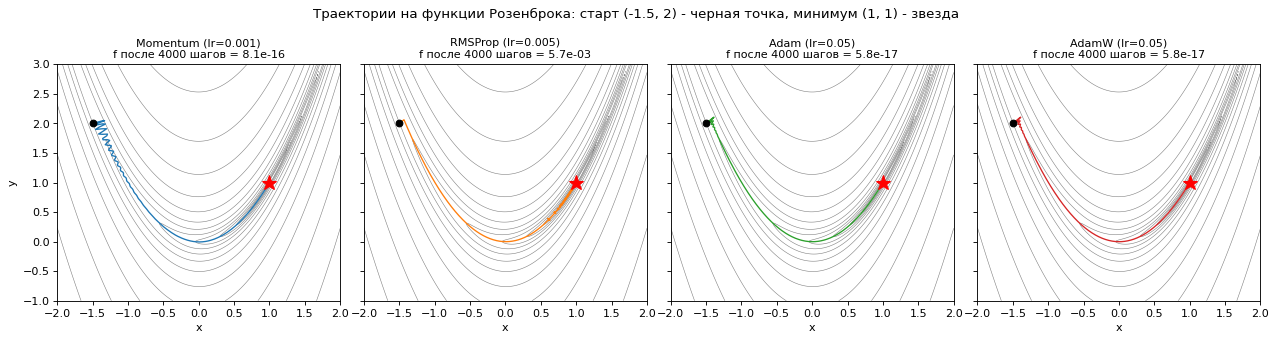

In [16]:
ROSEN_STEPS = 4000
with torch_threads(1):
    rosen_runs = {name: minimize_with(rosenbrock, ROSENBROCK_START, MY_OPTIMIZERS[name], ROSEN_STEPS, **kw)
                  for name, kw in ROSENBROCK_SETUP.items()}

OPT_COLORS = dict(zip(MY_OPTIMIZERS, plt.cm.tab10.colors))

grid_x, grid_y = np.meshgrid(np.linspace(-2, 2, 250), np.linspace(-1, 3, 250))
grid_z = (1 - grid_x) ** 2 + 100 * (grid_y - grid_x ** 2) ** 2

fig, axes = plt.subplots(1, 4, figsize=(16, 4.3), sharex=True, sharey=True, dpi=80)
for ax, (name, (path, values)) in zip(axes.flat, rosen_runs.items()):
    ax.contour(grid_x, grid_y, grid_z, levels=np.logspace(-1, 3.5, 14), colors="gray", linewidths=0.5)
    p = path.numpy()
    ax.plot(p[:, 0], p[:, 1], "-", color=OPT_COLORS[name], lw=1.2)
    ax.plot(*p[0], "ko", ms=6)
    ax.plot(1, 1, "r*", ms=14)
    lr_str = ", ".join(f"{k}={v:g}" for k, v in ROSENBROCK_SETUP[name].items() if k != "weight_decay")
    ax.set_title(f"{name} ({lr_str})\nf после {ROSEN_STEPS} шагов = {values[-1]:.1e}", fontsize=10)
    ax.set_xlim(-2, 2)
    ax.set_ylim(-1, 3)
for ax in axes:
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
fig.suptitle("Траектории на функции Розенброка: старт (-1.5, 2) - черная точка, минимум (1, 1) - звезда")
fig.tight_layout()
plt.show()

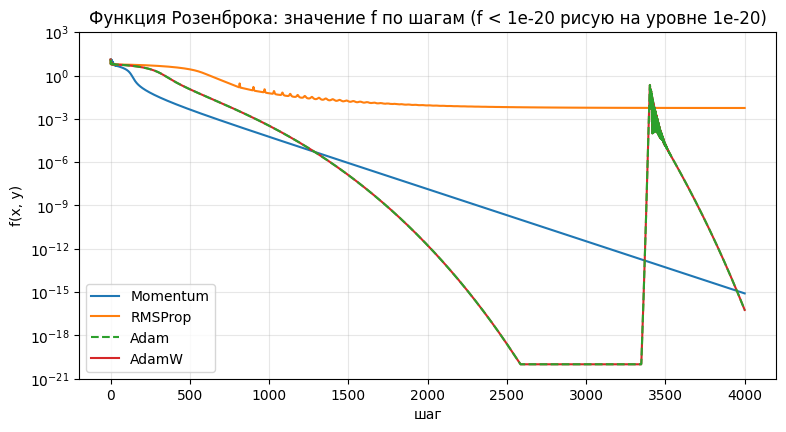

,шагов до f < 0.05,f после 4000 шагов,x в конце,y в конце
оптимизатор,,,,
Momentum,269,8.12e-16,1.000,1.000
RMSProp,1044,5.67e-03,0.989,0.985
Adam,571,5.79e-17,1.000,1.000
AdamW,571,5.79e-17,1.000,1.000


In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, (_, values) in rosen_runs.items():
    # Adam и AdamW (wd = 0) совпадают, поэтому Adam рисую пунктиром поверх
    style = dict(ls="--", zorder=3) if name == "Adam" else {}
    ax.plot(np.maximum(values, 1e-20), label=name, color=OPT_COLORS[name], **style)
ax.set_yscale("log")
ax.set_ylim(1e-21, 1e3)
ax.set_xlabel("шаг")
ax.set_ylabel("f(x, y)")
ax.set_title("Функция Розенброка: значение f по шагам (f < 1e-20 рисую на уровне 1e-20)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

rosen_table = pd.DataFrame([
    {"оптимизатор": name,
     "шагов до f < 0.05": next((i for i, v in enumerate(values) if v < 0.05), None),
     f"f после {ROSEN_STEPS} шагов": values[-1],
     "x в конце": path[-1, 0].item(), "y в конце": path[-1, 1].item()}
    for name, (path, values) in rosen_runs.items()]).set_index("оптимизатор")
rosen_table.style.format({f"f после {ROSEN_STEPS} шагов": "{:.2e}", "x в конце": "{:.3f}", "y в конце": "{:.3f}"}).format_index(
    escape="html", axis=1)

Что видно на функции Розенброка:
- Быстрее всех здесь Momentum (lr = 1e-3): до $f < 0.05$ за 269 шагов, а за 4000 шагов он доходит до $f \sim 10^{-15}$. Момент разгоняет точку вдоль дна оврага, в начале видны скачки поперек него.
- Adam и AdamW (при weight_decay = 0 они совпадают, как и должно быть, поэтому Adam нарисован пунктиром поверх AdamW) доходят до порога за 571 шаг и потом сходятся очень точно: примерно с 2600-го по 3350-й шаг $f < 10^{-20}$, и кривая лежит на нижней границе графика. Но видна особенность Adam с постоянным lr: когда градиент становится совсем маленьким, $v_t$ "забывает" старые большие градиенты, нормированный шаг снова становится порядка lr, и точку выбивает из минимума (всплеск около 3400-го шага), после чего она скатывается обратно.
- RMSProp доходит до дна оврага за 1044 шага, но дальше почти не продвигается ($f \approx 6\cdot 10^{-3}$ после 4000 шагов): шаг не уменьшается вместе с градиентом, и точка "дребезжит" поперек оврага (мелкие колебания на кривой).

На гладкой двумерной функции адаптивность особо не помогает: разный масштаб координат тут не главная проблема, и хорошо подобранный момент выигрывает.

## Сходимость на FashionMNIST

Модель - `BaseNetwork(nn.ReLU())` из задания (784-512-256-256-128-10), инициализация Кайминга (He normal, fan_in), которая для ReLU сохраняет масштаб активаций (см. задание 1). Чтобы сравнение было честным, все запуски стартуют с одних и тех же весов и видят батчи в одном и том же порядке, batch 128, 8 эпох.

Learning rate для каждого оптимизатора - типичный для него:
- Momentum: lr = 0.01, $\mu$ = 0.9;
- RMSProp: lr = 1e-3 (дефолтный 1e-2 для этой сети, скорее всего, великоват - это проверяю отдельно в конце раздела);
- Adam: lr = 1e-3;
- AdamW: lr = 1e-3, weight_decay = 0.05 (больше дефолтных 0.01, чтобы за несколько эпох эффект decay был заметен; при lr = 1e-3 веса за шаг умножаются на $1 - 5\cdot 10^{-5}$).

Логирую по итерациям лосс на батче, общую норму градиента (функция `grad_norm`) и нормы градиентов весов по слоям, по эпохам - лосс и точность на тесте и статистики весов по слоям. Полные веса сохраняю только в начале и в конце, чтобы не тратить память.

In [18]:
def he_init_(model):
    """Инициализация Кайминга (He normal, fan_in) под ReLU, смещения нулевые."""
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
            nn.init.zeros_(m.bias)
    return model


fm_x_train, fm_y_train, fm_x_test, fm_y_test = load_fashion_mnist()

# одни и те же начальные веса для всех запусков
set_seed(42)
fm_init_state = copy.deepcopy(he_init_(BaseNetwork(nn.ReLU())).state_dict())


def linear_layers(model):
    return [m for m in model.layers if isinstance(m, nn.Linear)]


def layer_weight_stats(model, prev_weights=None):
    """Норма весов (без смещений) по слоям и delta - насколько веса сдвинулись с прошлого замера."""
    stats = []
    for i, layer in enumerate(linear_layers(model)):
        w = layer.weight.detach()
        stats.append({"norm": w.norm().item(),
                      "delta": (w - prev_weights[i]).norm().item() if prev_weights is not None else 0.0})
    return stats


def train_fmnist(make_opt, epochs, batch_size=128, seed=42, snapshot_step=100):
    """Обучает BaseNetwork(ReLU) из fm_init_state.

    Логирует по итерациям лосс, общую норму градиента и нормы градиентов весов по слоям,
    по эпохам - test loss / accuracy и статистики весов. Полные веса сохраняются только в конце
    (и вектор всех параметров после snapshot_step итераций - для сравнения с torch.optim)."""
    set_seed(seed)
    model = BaseNetwork(nn.ReLU())
    model.load_state_dict(fm_init_state)
    opt = make_opt(model.parameters())
    layers = linear_layers(model)
    gen = torch.Generator().manual_seed(seed)  # одинаковый порядок батчей для всех оптимизаторов
    hist = {"loss": [], "grad_norm": [], "layer_grad_norms": [], "test_loss": [], "test_acc": [],
            "weight_stats": [layer_weight_stats(model)]}
    prev = [layer.weight.detach().clone() for layer in layers]
    step = 0
    start = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in iterate_batches(fm_x_train, fm_y_train, batch_size, generator=gen):
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            hist["grad_norm"].append(grad_norm(model))
            hist["layer_grad_norms"].append([layer.weight.grad.norm().item() for layer in layers])
            opt.step()
            hist["loss"].append(loss.item())
            step += 1
            if step == snapshot_step:
                hist["snapshot"] = nn.utils.parameters_to_vector(model.parameters()).detach().clone()
        test_loss, test_acc = evaluate(model, fm_x_test, fm_y_test)
        hist["test_loss"].append(test_loss)
        hist["test_acc"].append(test_acc)
        hist["weight_stats"].append(layer_weight_stats(model, prev))
        prev = [layer.weight.detach().clone() for layer in layers]
    hist["time"] = time.time() - start
    hist["layer_grad_norms"] = np.array(hist["layer_grad_norms"])
    hist["final_weights"] = [layer.weight.detach().numpy().ravel().copy() for layer in layers]
    return model, hist


def moving_average(x, k=50):
    """Скользящее среднее по окну k. Возвращает (номера итераций, значения), точка - в конце окна."""
    y = np.convolve(np.asarray(x), np.ones(k) / k, mode="valid")
    return np.arange(k - 1, k - 1 + len(y)), y


def fmnist_params_after(make_opt, steps, batch_size=128, seed=42):
    """Вектор параметров после steps итераций - тот же старт и тот же порядок батчей, что в train_fmnist."""
    set_seed(seed)
    model = BaseNetwork(nn.ReLU())
    model.load_state_dict(fm_init_state)
    opt = make_opt(model.parameters())
    gen = torch.Generator().manual_seed(seed)
    batches = iterate_batches(fm_x_train, fm_y_train, batch_size, generator=gen)
    for _, (xb, yb) in zip(range(steps), batches):
        loss = F.cross_entropy(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return nn.utils.parameters_to_vector(model.parameters()).detach()


FM_LAYER_NAMES = [f"W{i + 1} ({l.in_features}x{l.out_features})"
                  for i, l in enumerate(linear_layers(BaseNetwork(nn.ReLU())))]
print("Слои:", ", ".join(FM_LAYER_NAMES))

Слои: W1 (784x512), W2 (512x256), W3 (256x256), W4 (256x128), W5 (128x10)


In [19]:
FM_EPOCHS = 8
FM_SETUP = {
    "Momentum": dict(lr=0.01, momentum=0.9),
    "RMSProp": dict(lr=1e-3),
    "Adam": dict(lr=1e-3),
    "AdamW": dict(lr=1e-3, weight_decay=0.05),
}

fm_results = {}
for name, kw in FM_SETUP.items():
    _, fm_results[name] = train_fmnist(lambda ps: MY_OPTIMIZERS[name](ps, **kw), epochs=FM_EPOCHS)
    h = fm_results[name]
    print(f"{name:9s} test acc по эпохам: {' '.join(f'{a:.4f}' for a in h['test_acc'])}  ({h['time']:.0f} с)")

Momentum  test acc по эпохам: 0.8603 0.8700 0.8728 0.8778 0.8805 0.8860 0.8846 0.8880  (23 с)


RMSProp   test acc по эпохам: 0.8562 0.8657 0.8615 0.8696 0.8799 0.8739 0.8753 0.8609  (26 с)


Adam      test acc по эпохам: 0.8527 0.8717 0.8721 0.8772 0.8774 0.8858 0.8805 0.8860  (31 с)


AdamW     test acc по эпохам: 0.8437 0.8703 0.8688 0.8782 0.8709 0.8823 0.8827 0.8844  (33 с)


Сначала убедимся, что на настоящей задаче мой AdamW ведет себя ровно как `torch.optim.AdamW`: тот же старт, те же батчи, те же гиперпараметры.

MyAdamW      test acc: 0.8437 0.8703 0.8688 0.8782 0.8709 0.8823 0.8827 0.8844
torch AdamW  test acc: 0.8437 0.8703 0.8688 0.8782 0.8709 0.8823 0.8827 0.8844
max |разница лоссов| по всем 3752 итерациям: 0
max |разница весов| в конце: 0


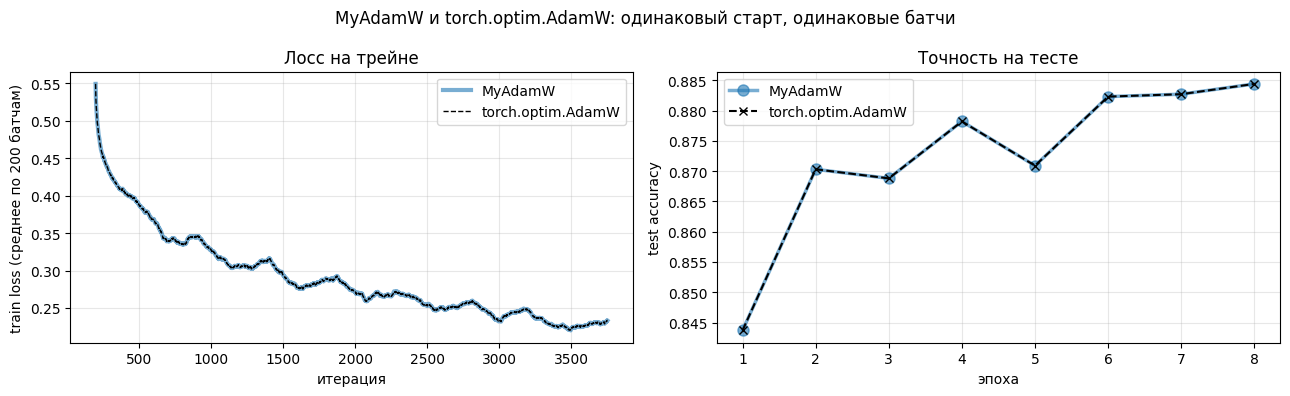

In [20]:
# главный оптимизатор - полностью тот же запуск с torch.optim.AdamW
_, fm_torch_adamw = train_fmnist(lambda ps: torch.optim.AdamW(ps, **FM_SETUP["AdamW"]), epochs=FM_EPOCHS)

adamw_mine, adamw_ref = fm_results["AdamW"], fm_torch_adamw
print("MyAdamW      test acc:", " ".join(f"{a:.4f}" for a in adamw_mine["test_acc"]))
print("torch AdamW  test acc:", " ".join(f"{a:.4f}" for a in adamw_ref["test_acc"]))
print(f"max |разница лоссов| по всем {len(adamw_mine['loss'])} итерациям: {np.abs(np.array(adamw_mine['loss']) - np.array(adamw_ref['loss'])).max():.3g}")
print(f"max |разница весов| в конце: {max(np.abs(a - b).max() for a, b in zip(adamw_mine['final_weights'], adamw_ref['final_weights'])):.3g}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(*moving_average(adamw_mine["loss"], 200), label="MyAdamW", lw=3, alpha=0.6)
axes[0].plot(*moving_average(adamw_ref["loss"], 200), "--", label="torch.optim.AdamW", lw=1, color="k")
axes[0].set_xlabel("итерация")
axes[0].set_ylabel("train loss (среднее по 200 батчам)")
axes[0].set_title("Лосс на трейне")
epochs_axis = np.arange(1, FM_EPOCHS + 1)
axes[1].plot(epochs_axis, adamw_mine["test_acc"], "o-", label="MyAdamW", lw=2.5, ms=8, alpha=0.6)
axes[1].plot(epochs_axis, adamw_ref["test_acc"], "x--", label="torch.optim.AdamW", color="k")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("test accuracy")
axes[1].set_title("Точность на тесте")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("MyAdamW и torch.optim.AdamW: одинаковый старт, одинаковые батчи")
fig.tight_layout()
plt.show()

Для остальных оптимизаторов полный второй прогон с torch-версией слишком долгий на CPU, поэтому сравниваю параметры после первых 100 итераций (у меня они сохраняются во время основного обучения):

In [21]:
# остальные - сравнение после 100 итераций (на полный прогон каждого не хватает времени CPU)
fm_init_vec = nn.utils.parameters_to_vector(fm_init_state.values())
twin_rows = []
for name, kw in FM_SETUP.items():
    ref_vec = fmnist_params_after(lambda ps: make_torch_twin(name, ps, **kw), steps=100)
    mine_vec = fm_results[name]["snapshot"]
    twin_rows.append({"оптимизатор": name, "torch-аналог": TORCH_TWINS[name][0].__name__,
                      "max |Δθ| (мой - torch) после 100 итераций": (mine_vec - ref_vec).abs().max().item(),
                      "max |θ - θ0| (насколько ушли от старта)": (mine_vec - fm_init_vec).abs().max().item()})
pd.DataFrame(twin_rows).set_index("оптимизатор")

,torch-аналог,max |Δθ| (мой - torch) после 100 итераций,max |θ - θ0| (насколько ушли от старта)
оптимизатор,,,
Momentum,SGD,0.0,0.079774
RMSProp,RMSprop,0.0,0.156247
Adam,Adam,0.0,0.060859
AdamW,AdamW,0.0,0.067642


Теперь сами графики сходимости: лосс на трейне в первой эпохе (среднее по 10 батчам, лог. шкала - чтобы был виден сам старт) и за все обучение (скользящее среднее по 200 батчам), лосс и точность на тесте по эпохам. В таблице под графиками - средний лосс на батче на разных отрезках первой эпохи.

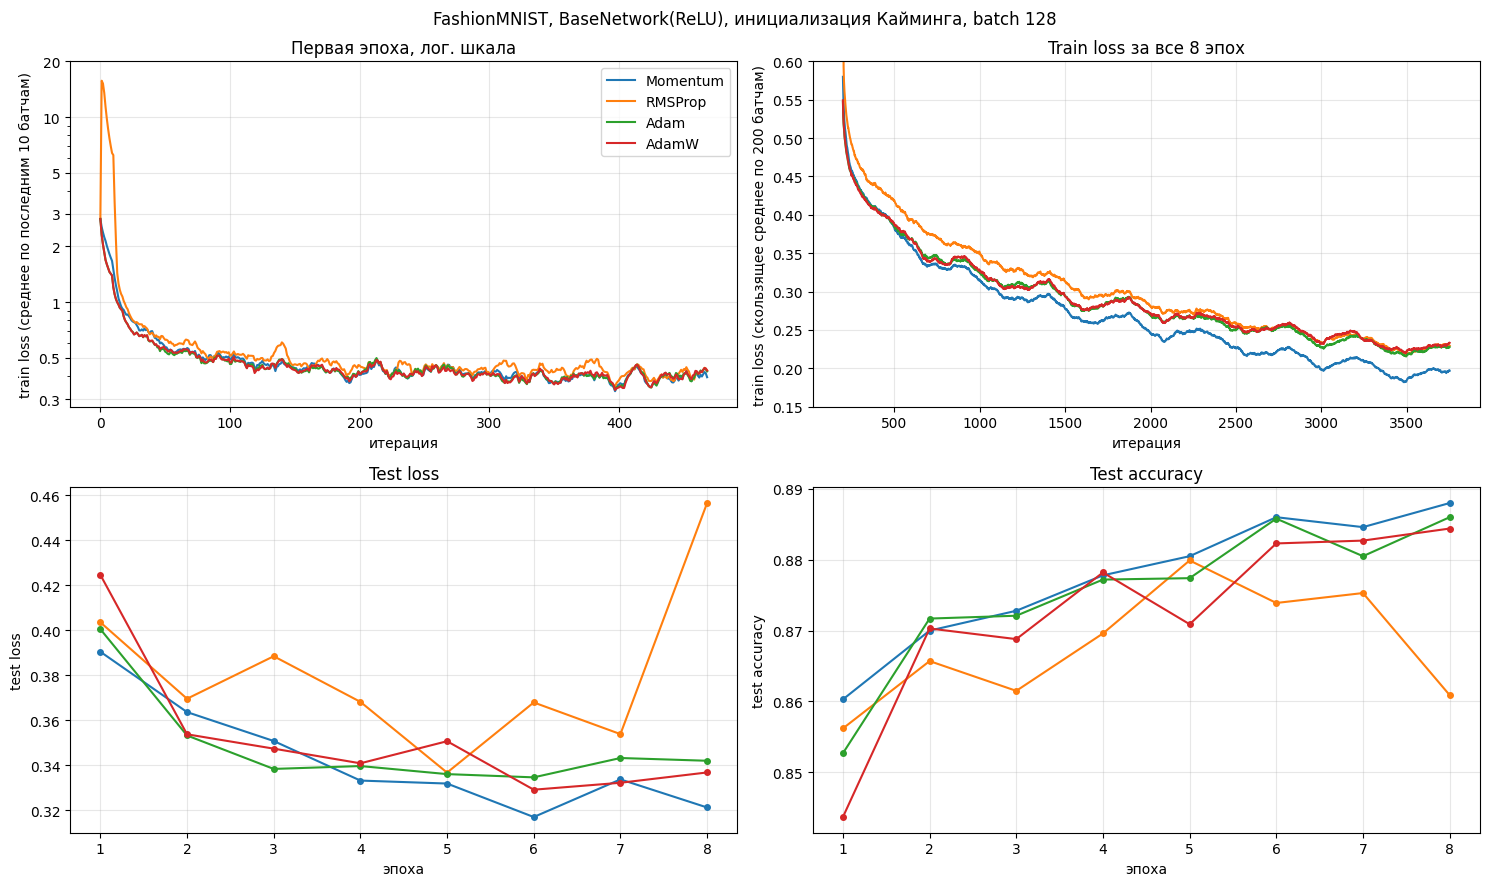

,итерации 0-49,итерации 50-99,итерации 100-199,итерации 200-468,test acc после 1-й эпохи
оптимизатор,,,,,
Momentum,0.913,0.520,0.443,0.404,0.8603
RMSProp,1.893,0.556,0.484,0.429,0.8562
Adam,0.808,0.502,0.440,0.405,0.8527
AdamW,0.812,0.507,0.439,0.404,0.8437


In [22]:
iters_per_epoch = len(fm_results["AdamW"]["loss"]) // FM_EPOCHS  # 469 батчей

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for name, h in fm_results.items():
    c = OPT_COLORS[name]
    # среднее по последним 10 батчам, в начале - по всем, что были (чтобы был виден сам старт)
    first_epoch = pd.Series(h["loss"][:iters_per_epoch]).rolling(10, min_periods=1).mean()
    axes[0, 0].plot(first_epoch.index, first_epoch.values, label=name, color=c)
    axes[0, 1].plot(*moving_average(h["loss"], 200), label=name, color=c)
    axes[1, 0].plot(epochs_axis, h["test_loss"], "o-", label=name, color=c, ms=4)
    axes[1, 1].plot(epochs_axis, h["test_acc"], "o-", label=name, color=c, ms=4)
axes[0, 0].set_yscale("log")
axes[0, 0].set_yticks([0.3, 0.5, 1, 2, 3, 5, 10, 20])
axes[0, 0].yaxis.set_major_formatter(ticker.FormatStrFormatter("%g"))
axes[0, 0].yaxis.set_minor_formatter(ticker.NullFormatter())
axes[0, 0].set_xlabel("итерация")
axes[0, 0].set_ylabel("train loss (среднее по последним 10 батчам)")
axes[0, 0].set_title("Первая эпоха, лог. шкала")
axes[0, 1].set_ylim(0.15, 0.6)
axes[0, 1].set_xlabel("итерация")
axes[0, 1].set_ylabel("train loss (скользящее среднее по 200 батчам)")
axes[0, 1].set_title("Train loss за все 8 эпох")
axes[1, 0].set_xlabel("эпоха")
axes[1, 0].set_ylabel("test loss")
axes[1, 0].set_title("Test loss")
axes[1, 1].set_xlabel("эпоха")
axes[1, 1].set_ylabel("test accuracy")
axes[1, 1].set_title("Test accuracy")
for ax in axes.flat:
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle("FashionMNIST, BaseNetwork(ReLU), инициализация Кайминга, batch 128")
fig.tight_layout()
plt.show()

# средний лосс на батче по отрезкам первой эпохи
loss_segments = [(0, 50), (50, 100), (100, 200), (200, iters_per_epoch)]
first_epoch_loss = pd.DataFrame(
    {f"итерации {a}-{b - 1}": [np.mean(h["loss"][a:b]) for h in fm_results.values()] for a, b in loss_segments},
    index=pd.Index(list(fm_results), name="оптимизатор"))
first_epoch_loss["test acc после 1-й эпохи"] = [h["test_acc"][0] for h in fm_results.values()]
first_epoch_loss.round({**{col: 3 for col in first_epoch_loss.columns}, "test acc после 1-й эпохи": 4})

Нормы градиентов: общая по всем параметрам для всех оптимизаторов и по слоям для AdamW (для сравнения рядом SGD с моментом). В таблице под графиками - средние нормы по слоям за последнюю эпоху.

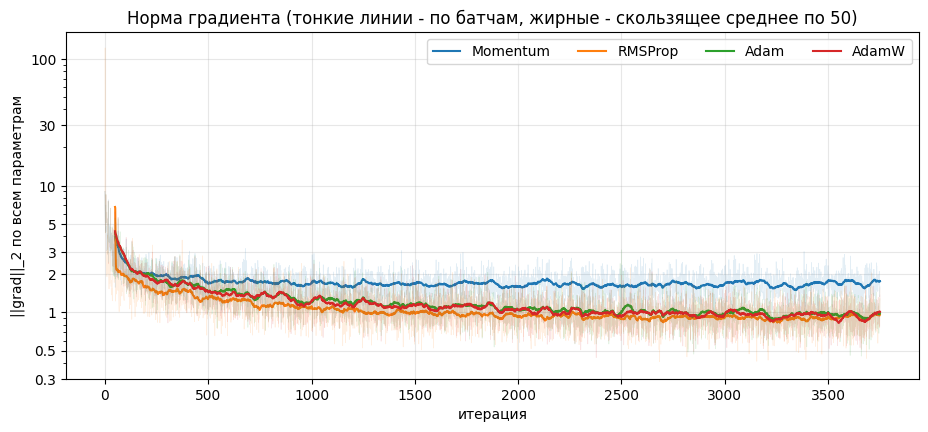

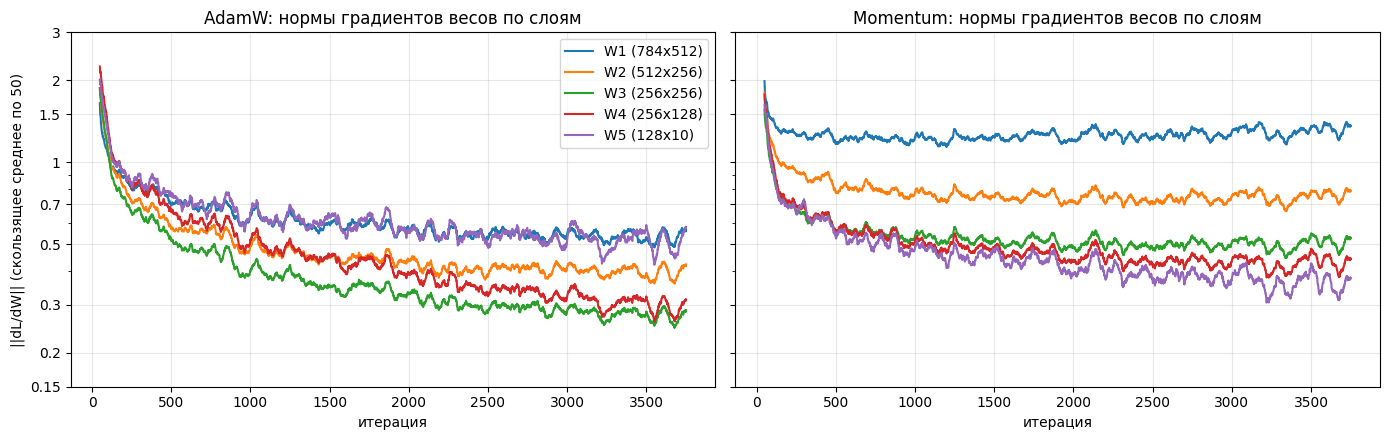

,W1 (784x512),W2 (512x256),W3 (256x256),W4 (256x128),W5 (128x10),вся сеть
оптимизатор,,,,,,
Momentum,1.30,0.75,0.50,0.43,0.36,1.69
RMSProp,0.50,0.44,0.26,0.25,0.49,0.91
Adam,0.54,0.41,0.29,0.32,0.52,0.97
AdamW,0.53,0.40,0.28,0.30,0.52,0.95


In [23]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for name, h in fm_results.items():
    ax.plot(h["grad_norm"], color=OPT_COLORS[name], alpha=0.12, lw=0.5)
    ax.plot(*moving_average(h["grad_norm"]), color=OPT_COLORS[name], label=name)
ax.set_yscale("log")
ax.set_yticks([0.3, 0.5, 1, 2, 3, 5, 10, 30, 100])
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%g"))
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
ax.set_xlabel("итерация")
ax.set_ylabel("||grad||_2 по всем параметрам")
ax.set_title("Норма градиента (тонкие линии - по батчам, жирные - скользящее среднее по 50)")
ax.legend(ncol=4)
ax.grid(alpha=0.3)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, ["AdamW", "Momentum"]):
    norms = fm_results[name]["layer_grad_norms"]
    for j, layer_name in enumerate(FM_LAYER_NAMES):
        ax.plot(*moving_average(norms[:, j]), label=layer_name)
    ax.set_yscale("log")
    ax.set_yticks([0.15, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3])
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%g"))
    ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax.set_xlabel("итерация")
    ax.set_title(f"{name}: нормы градиентов весов по слоям")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("||dL/dW|| (скользящее среднее по 50)")
axes[0].legend()
fig.tight_layout()
plt.show()

# средние нормы градиентов по слоям за последнюю эпоху
last_epoch_grad = pd.DataFrame({name: h["layer_grad_norms"][-iters_per_epoch:].mean(axis=0)
                                for name, h in fm_results.items()}, index=FM_LAYER_NAMES).T
last_epoch_grad["вся сеть"] = [np.mean(h["grad_norm"][-iters_per_epoch:]) for h in fm_results.values()]
last_epoch_grad.rename_axis("оптимизатор").round(2)

Распределения весов каждого слоя в начале (серая гистограмма, у всех одинаковая) и после обучения, а также распределение изменений весов $W_{end} - W_{init}$:

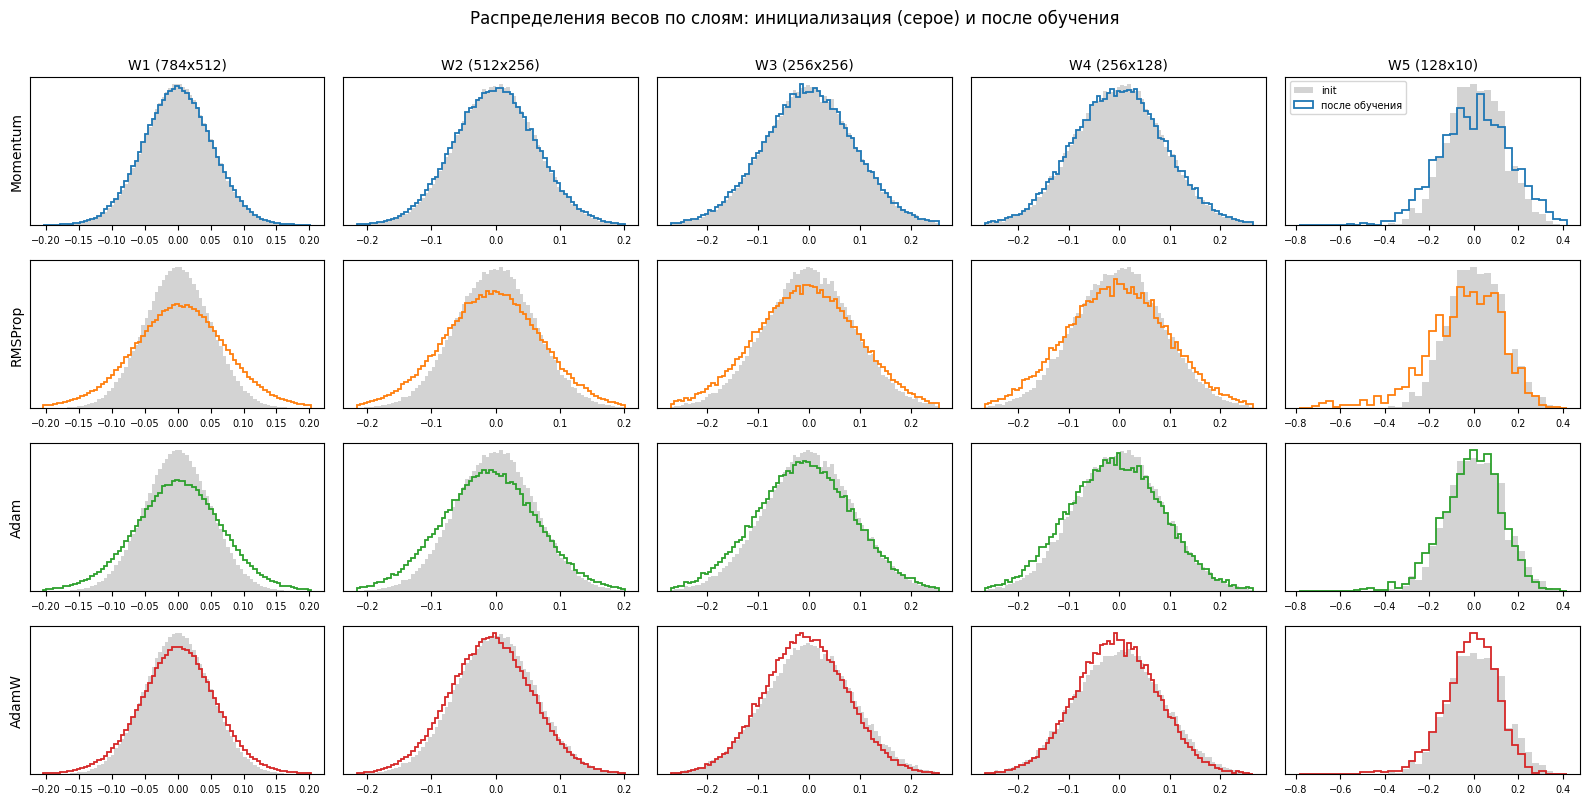

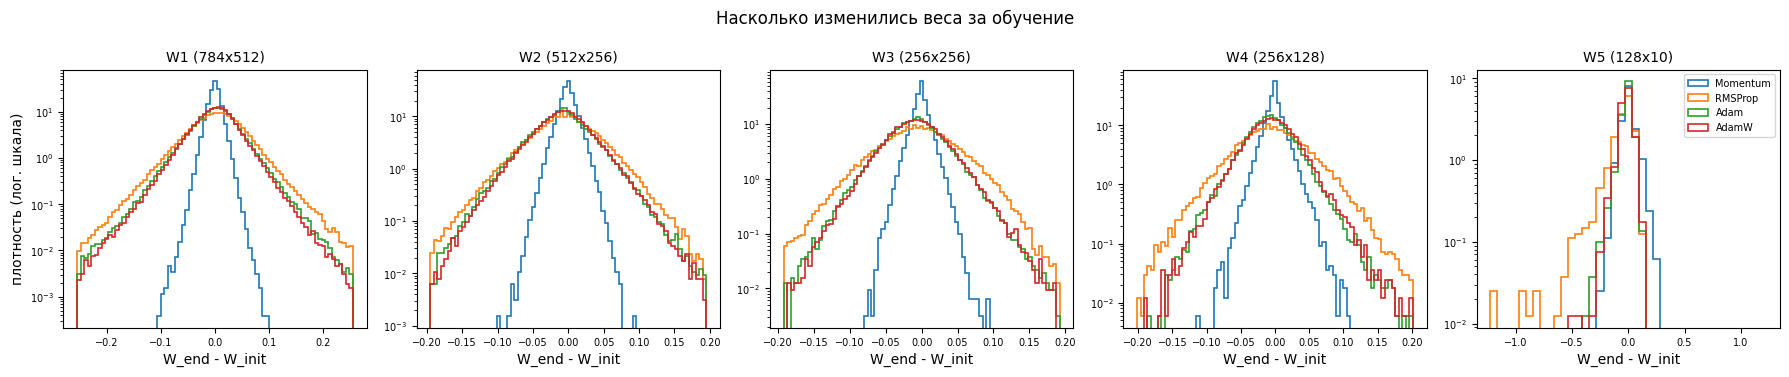

In [24]:
init_weights = [fm_init_state[f"layers.{2 * i}.weight"].numpy().ravel() for i in range(len(FM_LAYER_NAMES))]

fig, axes = plt.subplots(len(fm_results), len(FM_LAYER_NAMES), figsize=(16, 2.0 * len(fm_results)))
for j, layer_name in enumerate(FM_LAYER_NAMES):
    # общий диапазон по столбцу, чтобы распределения разных оптимизаторов было легко сравнивать
    lo = min(np.percentile(h["final_weights"][j], 0.5) for h in fm_results.values())
    hi = max(np.percentile(h["final_weights"][j], 99.5) for h in fm_results.values())
    bins = np.linspace(lo, hi, 80 if init_weights[j].size > 5000 else 40)
    for i, (name, h) in enumerate(fm_results.items()):
        ax = axes[i, j]
        ax.hist(init_weights[j], bins=bins, density=True, color="lightgray", label="init")
        ax.hist(h["final_weights"][j], bins=bins, density=True, histtype="step", lw=1.3,
                color=OPT_COLORS[name], label="после обучения")
        ax.set_yticks([])
        ax.tick_params(labelsize=7)
        if i == 0:
            ax.set_title(layer_name, fontsize=10)
        if j == 0:
            ax.set_ylabel(name, fontsize=10)
axes[0, -1].legend(fontsize=7)
fig.suptitle("Распределения весов по слоям: инициализация (серое) и после обучения", y=1.0)
fig.tight_layout()
plt.show()

# сами веса меняются не сильно, поэтому отдельно - распределение изменений W_end - W_init
fig, axes = plt.subplots(1, len(FM_LAYER_NAMES), figsize=(18, 3.8))
for j, (ax, layer_name) in enumerate(zip(axes, FM_LAYER_NAMES)):
    deltas = {name: h["final_weights"][j] - init_weights[j] for name, h in fm_results.items()}
    lim = max(np.percentile(np.abs(d), 99.9) for d in deltas.values())
    bins = np.linspace(-lim, lim, 80 if init_weights[j].size > 5000 else 40)
    for name, d in deltas.items():
        ax.hist(d, bins=bins, density=True, histtype="step", color=OPT_COLORS[name], label=name, lw=1.2)
    ax.set_yscale("log")
    ax.set_title(layer_name, fontsize=10)
    ax.set_xlabel("W_end - W_init")
    ax.tick_params(labelsize=7)
axes[0].set_ylabel("плотность (лог. шкала)")
axes[-1].legend(fontsize=7)
fig.suptitle("Насколько изменились веса за обучение")
fig.tight_layout()
plt.show()

Как менялись норма весов слоев и насколько веса сдвигались за эпоху. В таблице под графиком - сдвиг всех весов сети за эпоху, $\|W_e - W_{e-1}\|_F$ по всем слоям вместе:

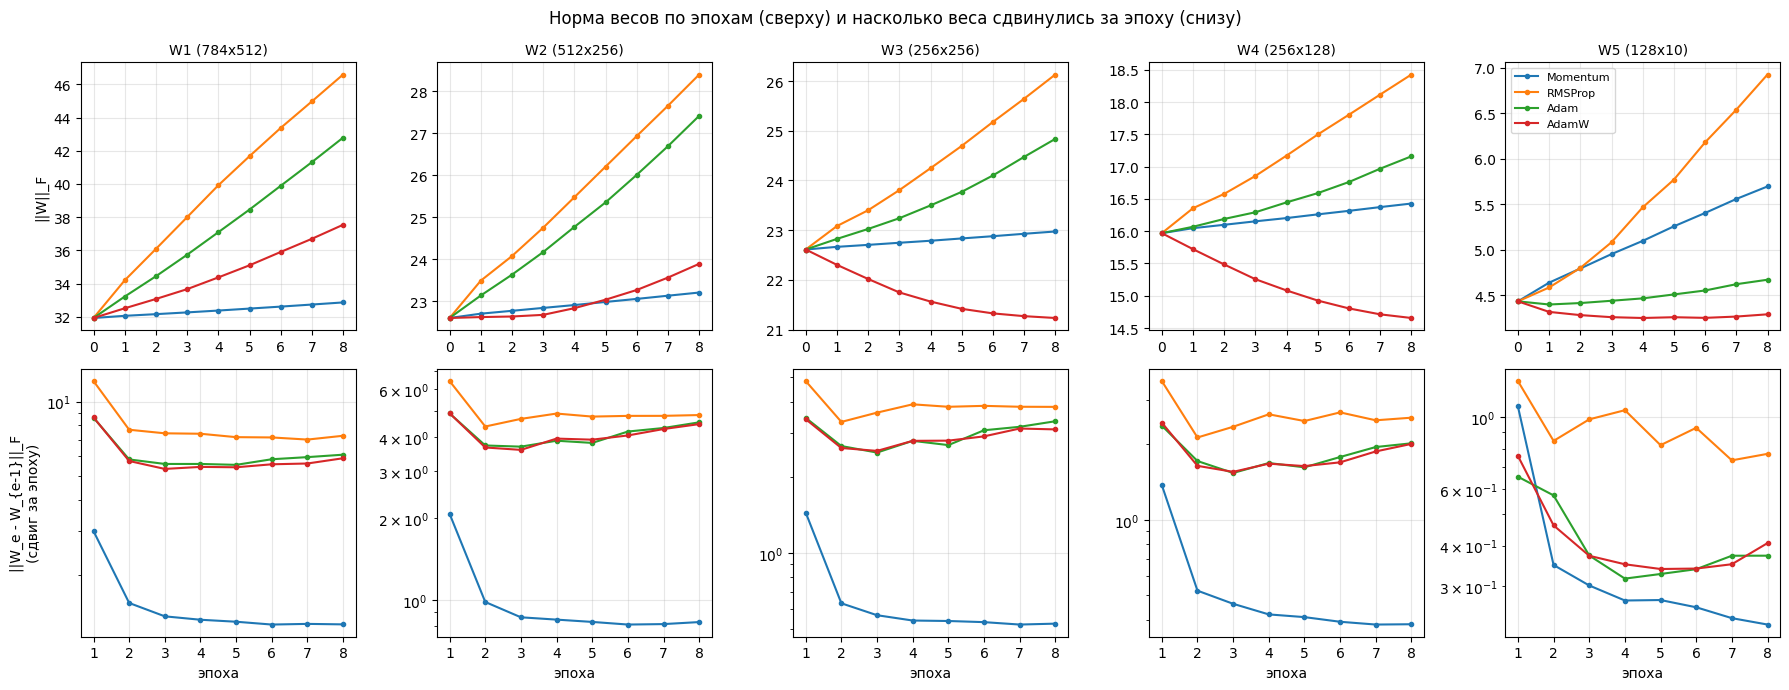

эпоха,1,2,3,4,5,6,7,8
оптимизатор,,,,,,,,
Momentum,4.30,2.03,1.79,1.73,1.70,1.65,1.65,1.66
RMSProp,15.02,9.73,9.84,10.10,9.78,9.85,9.67,9.89
Adam,10.76,7.63,7.33,7.56,7.43,8.03,8.26,8.55
AdamW,10.80,7.50,7.10,7.48,7.44,7.68,7.96,8.28


In [25]:
fig, axes = plt.subplots(2, len(FM_LAYER_NAMES), figsize=(18, 7))
epochs_with_init = np.arange(FM_EPOCHS + 1)
for name, h in fm_results.items():
    for j in range(len(FM_LAYER_NAMES)):
        norms = [s[j]["norm"] for s in h["weight_stats"]]
        deltas = [s[j]["delta"] for s in h["weight_stats"][1:]]
        axes[0, j].plot(epochs_with_init, norms, "o-", color=OPT_COLORS[name], ms=3, label=name)
        axes[1, j].plot(epochs_axis, deltas, "o-", color=OPT_COLORS[name], ms=3, label=name)
for j, layer_name in enumerate(FM_LAYER_NAMES):
    axes[0, j].set_title(layer_name, fontsize=10)
    axes[1, j].set_xlabel("эпоха")
    axes[1, j].set_yscale("log")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
    axes[0, j].set_xticks(epochs_with_init)
    axes[1, j].set_xticks(epochs_axis)
axes[0, 0].set_ylabel("||W||_F")
axes[1, 0].set_ylabel("||W_e - W_{e-1}||_F\n(сдвиг за эпоху)")
axes[0, -1].legend(fontsize=8)
fig.suptitle("Норма весов по эпохам (сверху) и насколько веса сдвинулись за эпоху (снизу)")
fig.tight_layout()
plt.show()

# сдвиг всех весов сети за каждую эпоху
weight_shift = pd.DataFrame(
    {name: [math.sqrt(sum(s["delta"] ** 2 for s in epoch_stats)) for epoch_stats in h["weight_stats"][1:]]
     for name, h in fm_results.items()},
    index=pd.Index(epochs_axis, name="эпоха")).T
weight_shift.rename_axis("оптимизатор").round(2)

Итоговая таблица:

In [26]:
fm_summary = pd.DataFrame([
    {"оптимизатор": name,
     "гиперпараметры": ", ".join(f"{k}={v:g}" for k, v in FM_SETUP[name].items()),
     "test acc": h["test_acc"][-1],
     "лучшая test acc": max(h["test_acc"]),
     "test loss": h["test_loss"][-1],
     "train loss (посл. эпоха)": np.mean(h["loss"][-len(h["loss"]) // FM_EPOCHS:]),
     "||W|| всех слоев": math.sqrt(sum(s["norm"] ** 2 for s in h["weight_stats"][-1])),
     "время, с": h["time"]}
    for name, h in fm_results.items()]).set_index("оптимизатор")
fm_summary.sort_values("test acc", ascending=False).style.format(
    {"test acc": "{:.4f}", "лучшая test acc": "{:.4f}", "test loss": "{:.4f}",
     "train loss (посл. эпоха)": "{:.4f}", "||W|| всех слоев": "{:.1f}", "время, с": "{:.0f}"})

,гиперпараметры,test acc,лучшая test acc,test loss,train loss (посл. эпоха),||W|| всех слоев,"время, с"
оптимизатор,,,,,,,
Momentum,"lr=0.01, momentum=0.9",0.8880,0.8880,0.3211,0.1920,49.5,23
Adam,lr=0.001,0.8860,0.8860,0.3419,0.2234,59.3,31
AdamW,"lr=0.001, weight_decay=0.05",0.8844,0.8844,0.3367,0.2275,51.6,33
RMSProp,lr=0.001,0.8609,0.8799,0.4565,0.2253,63.6,26


Отдельно проверю lr для RMSProp: с lr = 1e-3 он единственный к концу заметно хуже остальных. Тот же запуск (тот же старт, те же батчи) с дефолтным для torch lr = 1e-2 и с меньшим lr = 3e-4, для сравнения пунктиром Adam с lr = 1e-3:

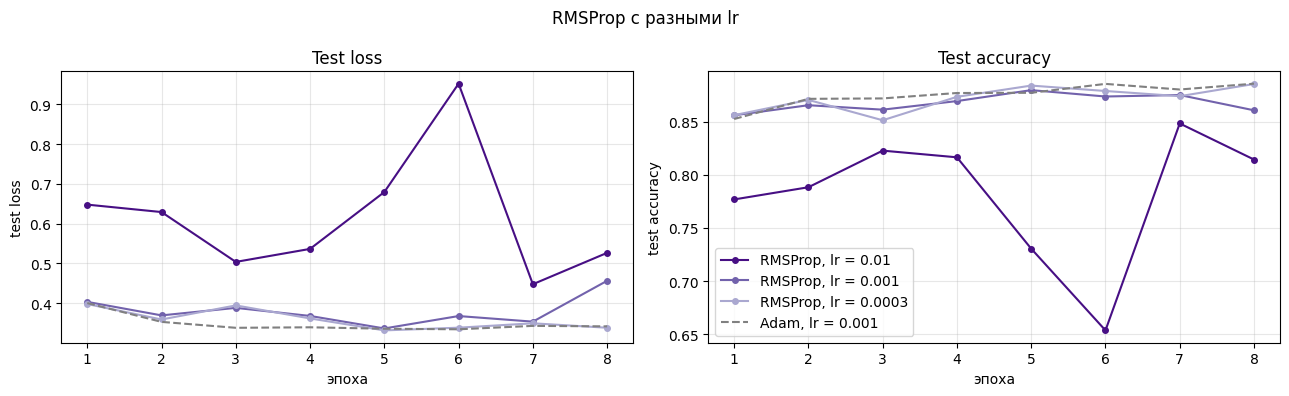

,test acc после 1-й эпохи,лучшая test acc,test acc в конце,test loss в конце,||W|| всех слоев
lr,,,,,
0.01,0.7769,0.8485,0.8145,0.5268,219.1
0.001,0.8562,0.8799,0.8609,0.4565,63.6
0.0003,0.8563,0.8857,0.8857,0.3384,51.1


In [27]:
# тот же запуск RMSProp с lr = 1e-2 (дефолт torch) и с lr = 3e-4
rmsprop_lr_runs = {1e-3: fm_results["RMSProp"]}
for lr in (1e-2, 3e-4):
    _, rmsprop_lr_runs[lr] = train_fmnist(lambda ps: MyRMSProp(ps, lr=lr), epochs=FM_EPOCHS)
rmsprop_lr_runs = dict(sorted(rmsprop_lr_runs.items(), reverse=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (lr, h), shade in zip(rmsprop_lr_runs.items(), [0.95, 0.7, 0.45]):
    for ax, key in zip(axes, ["test_loss", "test_acc"]):
        ax.plot(epochs_axis, h[key], "o-", color=plt.cm.Purples(shade), ms=4, label=f"RMSProp, lr = {lr:g}")
for ax, key in zip(axes, ["test_loss", "test_acc"]):
    ax.plot(epochs_axis, fm_results["Adam"][key], "--", color="gray", label="Adam, lr = 0.001")
    ax.set_xlabel("эпоха")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("test loss")
axes[0].set_title("Test loss")
axes[1].set_ylabel("test accuracy")
axes[1].set_title("Test accuracy")
axes[1].legend()
fig.suptitle("RMSProp с разными lr")
fig.tight_layout()
plt.show()

pd.DataFrame([
    {"lr": f"{lr:g}",
     "test acc после 1-й эпохи": h["test_acc"][0],
     "лучшая test acc": max(h["test_acc"]),
     "test acc в конце": h["test_acc"][-1],
     "test loss в конце": h["test_loss"][-1],
     "||W|| всех слоев": math.sqrt(sum(s["norm"] ** 2 for s in h["weight_stats"][-1]))}
    for lr, h in rmsprop_lr_runs.items()]).set_index("lr").round(4).round({"||W|| всех слоев": 1})

In [28]:
# освобождаю память: данные и полные веса дальше не нужны
del fm_x_train, fm_y_train, fm_x_test, fm_y_test, fm_torch_adamw, adamw_ref, rmsprop_lr_runs
for h in fm_results.values():
    h.pop("final_weights", None)
    h.pop("snapshot", None)

## Выводы

- Реализация совпадает с torch: у MyAdamW и `torch.optim.AdamW` одинаковые лоссы на всех 3752 итерациях и одинаковые веса в конце, Momentum, RMSProp и Adam совпадают со своими аналогами после 100 итераций. Так что все различия ниже - это различия самих алгоритмов.
- Сходятся все. У Momentum, Adam и AdamW точность на тесте через 8 эпох 88.4-88.8%, и разница между ними меньше, чем скачки точности от эпохи к эпохе (0.5-1%), так что при одном сиде их можно считать одинаковыми. Выбивается RMSProp с lr = 1e-3: к концу test loss вырос до 0.457, точность упала до 86.1% (лучшая была 88.0% на 5-й эпохе). Отдельная проверка показала, что дело в lr: с lr = 3e-4 RMSProp ведет себя как остальные (88.57%, test loss 0.338, без провала в конце), а с дефолтным 1e-2 обучение совсем нестабильное (норма весов выросла до 219). Почему RMSProp нужен lr меньше, чем Adam: у него в числителе нет усреднения градиента, поэтому шаг $g_t/\sqrt{v_t}$ по каждой координате порядка lr, даже когда градиент - это в основном шум мини-батча, а у Adam $\hat m_t$ этот шум частично усредняет. Это видно и по весам: после первой эпохи веса RMSProp сдвигаются за эпоху на 9.7-10.1 (по норме), а у Adam - на 7.3-8.6.
- На старте адаптивные методы здесь не быстрее (график первой эпохи и таблица под ним). Momentum, Adam и AdamW стартуют одинаково: средний лосс на батче за первые 50 итераций 0.81-0.91, за итерации 50-99 - 0.50-0.52. А у RMSProp после первого же шага лосс на батче подскакивает с 2.8 до 28.6 (за первые 50 итераций в среднем 1.89): без поправки на смещение его первый шаг равен $10\cdot$lr$\cdot\mathrm{sign}(g) = 0.01\cdot\mathrm{sign}(g)$ по каждому весу, для этой сети это слишком много. После первой эпохи по точности впереди Momentum (86.03%), у Adam 85.27%, у AdamW 84.37%. Лосс на трейне в последней эпохе у SGD с моментом тоже ниже: 0.192 против 0.22-0.23 у Adam, AdamW и RMSProp. Сеть с инициализацией Кайминга хорошо обусловлена, и SGD с моментом при нормальном lr ничем не хуже.
- Норма градиента после первых ~200 итераций выходит на плато: в последней эпохе у Momentum 1.69, у Adam, AdamW и RMSProp 0.91-0.97. Это в основном шум мини-батча, про качество она напрямую ничего не говорит. По слоям у Momentum градиент первого слоя (1.30) в 2.6-3.6 раза больше, чем у последних трех (0.36-0.50), а у AdamW все слои в пределах 0.28-0.53.
- У SGD с моментом веса за 8 эпох почти не изменились: суммарная норма 49.5 при 48.1 на старте, изменения весов первого слоя в пределах $\pm 0.1$, а сдвиг за эпоху после первой эпохи почти постоянный (1.65-2.03). У Adam, AdamW и RMSProp шаг по каждой координате порядка lr и не зависит от величины градиента, поэтому веса все время "гуляют": сдвиг за эпоху не уменьшается (у Adam 7.3-8.6 в эпохах 2-8, у RMSProp около 10), и нормы растут почти линейно (Adam 59.3, RMSProp 63.6).
- AdamW держит норму весов: 51.6 против 59.3 у Adam при том же lr, а у W3-W5 норма даже уменьшилась (W4: 16.0 -> 14.7), тогда как у остальных оптимизаторов она растет во всех слоях. Точность та же в пределах шума (88.44% против 88.60%), test loss чуть ниже (0.337 против 0.342): за 8 эпох сеть еще почти не переобучается, так что выигрыш от регуляризации маленький.
- Время - 23-33 с на 8 эпох: Momentum быстрее всех (23 с), у адаптивных методов на каждый параметр больше буферов и операций (26-33 с).

Итого: все 4 оптимизатора совпадают с `torch.optim`, на FashionMNIST доходят примерно до 88% (RMSProp - при lr = 3e-4), а главное практическое отличие AdamW от Adam здесь - контроль нормы весов.

## Источники

- B. T. Polyak. Some methods of speeding up the convergence of iteration methods, 1964 (heavy ball): https://doi.org/10.1016/0041-5553(64)90137-5
- Ю. Е. Нестеров. Метод решения задачи выпуклого программирования со скоростью сходимости O(1/k^2), 1983.
- I. Sutskever, J. Martens, G. Dahl, G. Hinton. On the importance of initialization and momentum in deep learning, ICML 2013: http://proceedings.mlr.press/v28/sutskever13.html
- J. Duchi, E. Hazan, Y. Singer. Adaptive Subgradient Methods for Online Learning and Stochastic Optimization, JMLR 2011: https://jmlr.org/papers/v12/duchi11a.html
- M. Zeiler. ADADELTA: An Adaptive Learning Rate Method, 2012: https://arxiv.org/abs/1212.5701
- G. Hinton, N. Srivastava, K. Swersky. Neural Networks for Machine Learning, lecture 6e (RMSProp): https://www.cs.toronto.edu/~tijmen/csc321/slides/lecture_slides_lec6.pdf
- D. Kingma, J. Ba. Adam: A Method for Stochastic Optimization, 2014: https://arxiv.org/abs/1412.6980
- I. Loshchilov, F. Hutter. Decoupled Weight Decay Regularization, 2017: https://arxiv.org/abs/1711.05101
- T. Dozat. Incorporating Nesterov Momentum into Adam, ICLR 2016 Workshop: https://openreview.net/forum?id=OM0jvwB8jIp57ZJjtNEZ
- S. Reddi, S. Kale, S. Kumar. On the Convergence of Adam and Beyond (AMSGrad), ICLR 2018: https://openreview.net/forum?id=ryQu7f-RZ
- Документация PyTorch, `torch.optim` (формулы и исходники SGD, Adagrad, Adadelta, RMSprop, Adam, AdamW, NAdam): https://pytorch.org/docs/stable/optim.html
- S. Ruder. An overview of gradient descent optimization algorithms: https://ruder.io/optimizing-gradient-descent/